# Recommending Steam Games: Popularity vs. Collaborative Filtering vs. a Linear Autoencoder

This notebook asks a simple question: given the games a Steam player has actually played, can we rank the rest of the catalog so that a game we hid from them appears near the top? We answer it by comparing seven recommenders under one evaluation protocol, from a popularity baseline to the collaborative-filtering models covered in class, and one method from outside the course, EASE.

Our main finding is that EASE ranks the hidden game highest, with a properly tuned implicit ALS model about ten percent behind. Most of the notebook is about whether that finding can be trusted. We audit the raw file before using it, test the evaluation code against cases with known answers, check that every model was tuned with the best setting inside its search range rather than on its edge, compare our hand-written models with a reference library, and re-run the comparison on new splits and a different choice of hidden game.

The notebook follows the five sections of the presentation:

| Section | What it covers |
|---|---|
| 1 | The predictive task, how we evaluate it, the baselines, and how we judge validity |
| 2 | Where the data comes from, an audit of the raw file, exploratory analysis, and pre-processing |
| 3 | How the task becomes an ML problem, and the seven models with their trade-offs |
| 4 | The evaluation code and its tests, tuning, final results, three outside checks, and error analysis |
| 5 | Related work, conclusions, and limitations |

# 1. Predictive task

We start by defining exactly what a model is asked to do, because every later choice (the split, the metrics, the baselines) follows from it.

The task is **top-N recommendation from implicit feedback**. For each player $u$ with a set of played games $I_u$, a model produces a ranked list over every game $u$ has not played. One of the player's played games is hidden beforehand, and the model is judged on where that game lands in its ranking. At prediction time the model sees only the player's other played games: no timestamps, no game metadata, and nothing about the hidden game itself.

We frame it this way because of what the data contains. Steam has no star ratings; we only observe which games a player owns and how many minutes they played each one. "Played" is therefore our positive signal, and ranking, rather than predicting a rating, is what a storefront actually needs. Because the hidden game is chosen at random rather than being the most recent one, this is a *recover-a-hidden-game* task. We do not claim to predict the next game a player will pick up, and we return to this limitation in Section 4.4.

**How we evaluate it.** Each player contributes one test game and one validation game, and the rest of their games are used for training. Every model is tuned on validation only, then refit on training plus validation and scored once on test. Each model ranks *all* the games the player has not played, because evaluating against a small sample of negatives is known to reorder models (Krichene & Rendle, 2020). Since each player has exactly one relevant game, Recall@K equals HitRate@K and precision adds no information, so we report four metrics, each with a 95% bootstrap interval over players:

- **HR@10**: is the hidden game in the top ten at all?
- **NDCG@10**: how high in the top ten is it?
- **MRR**: the reciprocal of its rank, over the whole list.
- **AUC**: the share of other games ranked below it.

Ties are resolved pessimistically, so a model cannot gain by giving many games the same score.

**What we compare against.** *Random* is a sanity check: its HR@10 must match the theoretical value of ten divided by the number of candidate games. *Popularity* is the standard non-personalized baseline and is hard to beat on long-tailed data. The course models (cosine *Item-kNN*, implicit *ALS*, *BPR*, and *PureSVD*, the truncated SVD the course contrasts with latent-factor models) serve as comparison points for *EASE*, the method from outside the course.

**How we judge validity.** A result only counts if Random lands at chance, if a personalized model beats Popularity with a paired confidence interval that excludes zero, and if the gain holds across player activity levels rather than only for heavy players. We also report how much of the catalog each model recommends, so that accuracy is not bought by showing only blockbusters. Finally, the evaluation code must pass known-answer tests (Section 4.1), our ALS and BPR must agree with a reference library, and the model ordering must survive re-drawing the split (Section 4.4).

This is still an offline proxy. A hidden played game is not proof that the player would prefer it over the other recommendations, and the random split is not a temporal one. Section 4.4 stress-tests that choice using the file's `playtime_2weeks` field.

# 2. Data, exploratory analysis, and pre-processing

With the task defined, we turn to the data it runs on. This section explains where the file comes from, checks the raw records for problems a cleaned table would hide, explores the patterns that shape our modeling choices, and ends with the matrices every model will use.

## 2.1 Context: where the data comes from
We use the *Steam Video Game and Bundle Data* from the UCSD McAuley Lab ([dataset page](https://mcauleylab.ucsd.edu/public_datasets/data/datasets.html)), specifically the **Australian users and their items** file. Each record is one public Steam profile with the games it owns and, for each game, `playtime_forever` (total minutes) and `playtime_2weeks` (minutes in the two weeks before the crawl). The profiles were crawled for O'Neill et al. (IMC 2016), a measurement study of how people use Steam, as credited on the dataset page.

One practical detail: each line of the file is a Python dict literal with single quotes, not strict JSON, so `json.loads` fails on it. The loader below falls back to `ast.literal_eval`.

Parsing every profile is slow, and some models need dense game-by-game matrices, so we keep a random fraction of players (`SAMPLE_FRAC`). The sample is drawn line by line with a seeded generator rather than by taking the first lines of the file, in case the file is ordered.

In [1]:
import os, gzip, json, ast, time, itertools, warnings
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from sklearn.decomposition import TruncatedSVD
from sklearn.manifold import TSNE
from sklearn.preprocessing import normalize
from IPython.display import display, Markdown
import re

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False, "axes.spines.right": False})

SEED = 42
rng = np.random.default_rng(SEED)

# ---------------- experiment configuration ----------------
SAMPLE_FRAC    = 0.35   # fraction of users (random) to load
MIN_PLAYTIME   = 0      # minutes; an interaction counts as "played" if playtime_forever > MIN_PLAYTIME
MIN_USER_ITEMS = 5      # k-core: min played games per user
MIN_ITEM_USERS = 20     # k-core: min players per game
TOP_K          = 10
TUNE_USERS     = 5000   # validation users used for hyper-parameter search
N_RESPLITS     = 3      # extra random re-splits used to check that the model ordering is stable
FAST_MODE      = False  # True = tiny grids / fewer iterations (for a quick smoke test)

DATA_DIR  = Path("data"); DATA_DIR.mkdir(exist_ok=True)
DATA_PATH = DATA_DIR / "australian_users_items.json.gz"
DATA_URL  = "https://mcauleylab.ucsd.edu/public_datasets/data/steam/australian_users_items.json.gz"

if not DATA_PATH.exists():
    print("Downloading Steam user-item data ...")
    urlretrieve(DATA_URL, DATA_PATH)
print(f"{DATA_PATH}  ({DATA_PATH.stat().st_size / 2**20:.1f} MB)")

data/australian_users_items.json.gz  (74.0 MB)


In [2]:
def parse_line(line):
    # The UCSD Steam files are Python-literal lines, not strict JSON.
    try:
        return json.loads(line)
    except json.JSONDecodeError:
        return ast.literal_eval(line)

records, names = [], {}
n_profiles = n_private = 0
UID = re.compile(r"'user_id': u?'([^']*)'"); seen_uid, n_dup_lines = set(), 0   # cheap whole-file duplicate count (no parsing)
t0 = time.time()
with gzip.open(DATA_PATH, "rt", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        n_profiles += 1
        mu = UID.search(line[:200])
        if mu:
            n_dup_lines += mu.group(1) in seen_uid; seen_uid.add(mu.group(1))
        if rng.random() > SAMPLE_FRAC:          # random user sample; skipped lines are never parsed
            continue
        obj = parse_line(line)
        items = obj.get("items") or []
        if not items:                            # private / empty library
            n_private += 1
            continue
        uid = obj["user_id"]
        for e in items:
            iid = str(e["item_id"])
            names.setdefault(iid, e.get("item_name"))
            records.append((uid, iid, float(e.get("playtime_forever") or 0), float(e.get("playtime_2weeks") or 0)))

raw = pd.DataFrame(records, columns=["user_id", "item_id", "playtime", "playtime_2w"]).drop_duplicates(["user_id", "item_id"])
raw["hours"]  = raw.playtime / 60
raw["played"] = raw.playtime > MIN_PLAYTIME
raw["recent"] = raw.playtime_2w > 0
print(f"Parsed in {time.time()-t0:.0f}s | profiles in file: {n_profiles:,} | sampled with empty library: {n_private:,}")
print(f"Whole file: {len(seen_uid):,} distinct user ids in {n_profiles:,} lines ({n_dup_lines:,} repeated lines; merged by drop_duplicates above)")
print(f"Loaded interactions: {len(raw):,} | users: {raw.user_id.nunique():,} | games: {raw.item_id.nunique():,}")
raw.head()

Parsed in 26s | profiles in file: 88,310 | sampled with empty library: 5,877
Whole file: 87,626 distinct user ids in 88,310 lines (684 repeated lines; merged by drop_duplicates above)
Loaded interactions: 1,810,138 | users: 24,793 | games: 10,094


,user_id,item_id,playtime,playtime_2w,hours,played,recent
0,doctr,300,1131.0,0.0,18.850000,True,False
1,doctr,20,89.0,0.0,1.483333,True,False
2,doctr,50,178.0,0.0,2.966667,True,False
3,doctr,70,108.0,0.0,1.800000,True,False
4,doctr,130,313.0,0.0,5.216667,True,False


## 2.2 Raw-file audit: what the cleaned table would hide
Before building anything on the data, we check the raw records for three problems that could quietly bias a recommender.

The first is **repeated profiles**. If the same player appeared twice as two different players, the game hidden from one copy would sit in the other copy's training row, which hands the answer to any item-based model. The loader merges repeats by `user_id`, and the cell above prints how many it found.

The second is **games that are owned but never chosen**. Steam adds some titles to libraries automatically, such as test clients and betas. They are owned by a huge number of profiles and played by almost none, so they look popular without telling us anything about taste.

The third is a field we do not train on but will use later. `playtime_2weeks` is the only time-related signal in the file, and Section 4.4 uses it to stress-test our random split. The table below lists the most-owned games with their owners, players, and recent players.

In [3]:
g = raw.groupby("item_id").agg(owners=("user_id", "size"), players=("played", "sum"), recent_players=("recent", "sum"))
g["played share"] = g.players / g.owners
g.insert(0, "game", [names.get(i) for i in g.index])
top_owned = g.sort_values("owners", ascending=False).head(12).reset_index(drop=True)
display(top_owned.style.format({"played share": "{:.0%}"}).background_gradient(subset=["played share"], cmap="RdYlGn", vmin=0, vmax=1)
        .set_caption("Most-owned titles in the sample: ownership is not the same as play"))

ghost = g[(g.owners >= 500) & (g["played share"] < 0.25)].sort_values("owners", ascending=False)
u_recent = raw.groupby("user_id").recent.any()
print(f"Titles with >= 500 owners that under 25% of owners ever launched: {len(ghost)}"
      f"  (e.g. {', '.join(str(x) for x in ghost.game.head(4))})")
print(f"Owned pairs with zero playtime: {(~raw.played).mean():.1%}")
print(f"Pairs played in the last two weeks: {raw.recent.mean():.1%} | profiles with at least one such game: {u_recent.mean():.1%}")

,game,owners,players,recent_players,played share
0,Dota 2 Test,17249,1253,2,7%
1,Counter-Strike: Global Offensive,15170,14979,4828,99%
2,Garry's Mod,15015,14583,1528,97%
3,Unturned,13442,11997,779,89%
4,Left 4 Dead 2 Beta,12833,457,2,4%
5,Left 4 Dead 2,12833,12038,666,94%
6,Terraria,10316,10046,777,97%
7,Warframe,8881,7229,609,81%
8,Portal 2,8515,7884,165,93%
9,Counter-Strike: Source,8404,7511,279,89%


Titles with >= 500 owners that under 25% of owners ever launched: 78  (e.g. Dota 2 Test, Left 4 Dead 2 Beta, Patch testing for Chivalry, Killing Floor Mod: Defence Alliance 2)
Owned pairs with zero playtime: 36.8%
Pairs played in the last two weeks: 2.7% | profiles with at least one such game: 51.1%


## 2.3 Exploratory analysis
The audit suggests that ownership and play are different things. The exploratory analysis checks how far that goes, and answers two further questions that matter for modeling: how concentrated play is on a few games, and whether popular games are also the ones people play for long. The answers decide our positive signal, tell us which baseline will be hard to beat, and tell us how to break down the results later.

,value
Users,"24,793.0000"
Games,"10,094.0000"
"Owned (user, game) pairs","1,810,138.0000"
Played pairs (playtime > threshold),"1,143,484.0000"
Share of owned pairs never played,0.3683
Median games owned per user,40.0000
Median games played per user,28.0000
Matrix density (owned),0.0072
Gini of games' owner counts,0.8401


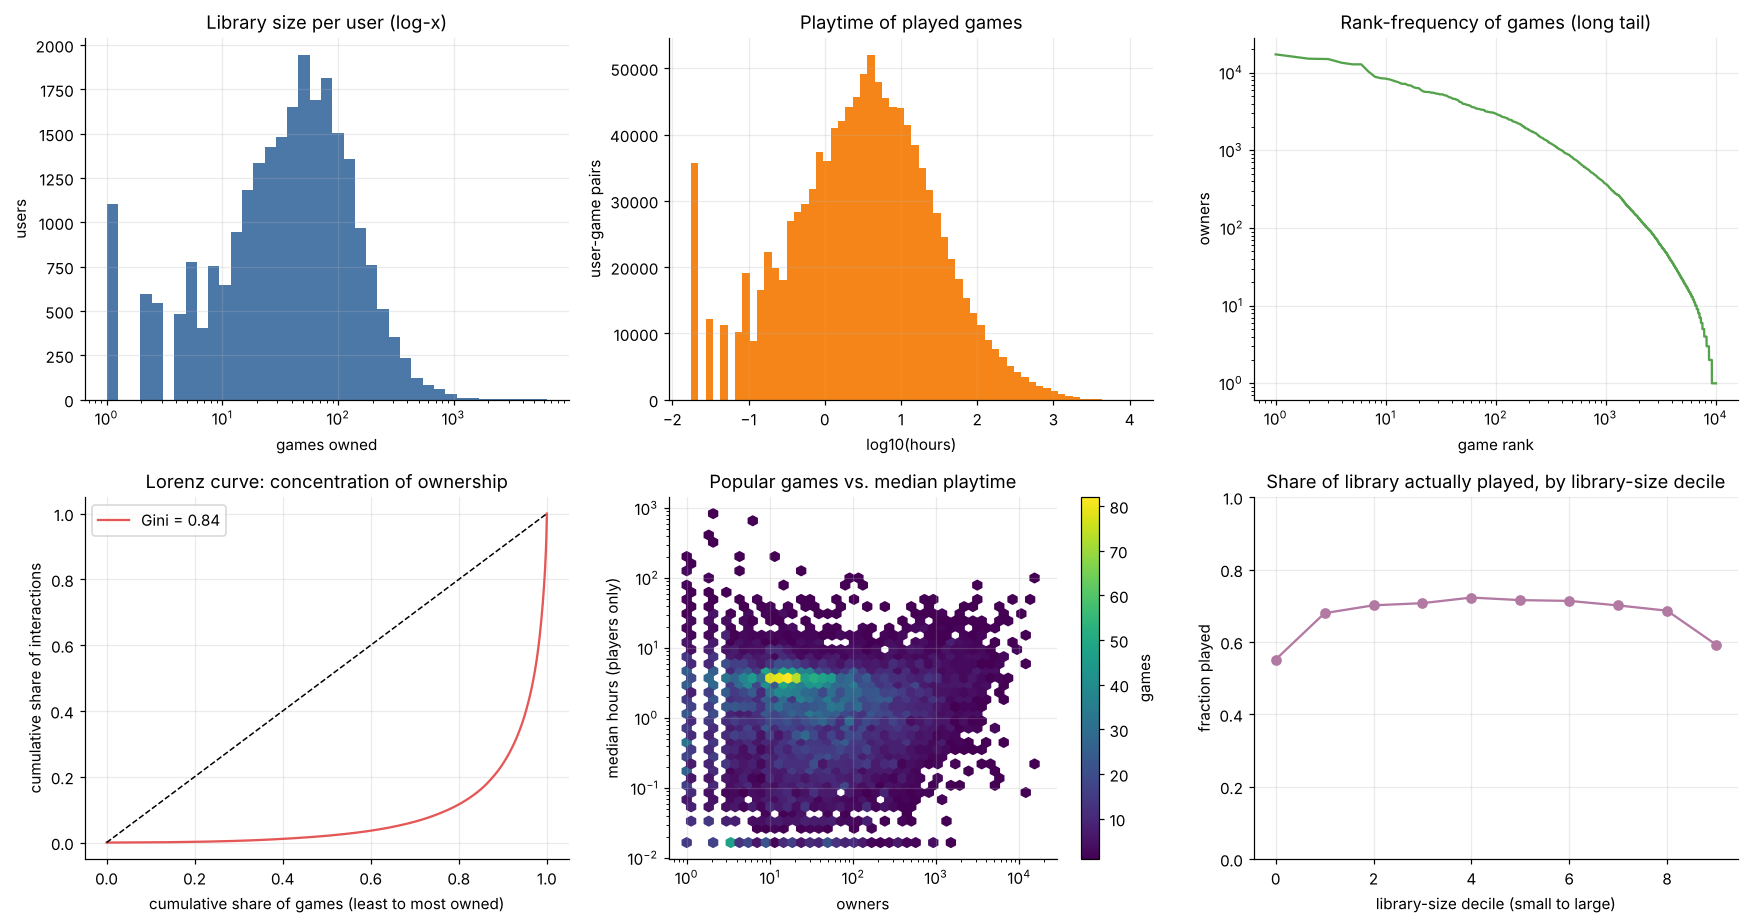

Spearman(owners, median hours played) = 0.012


,most owned,owners,most played (total),hours
0,Dota 2 Test,17249,Counter-Strike: Global Offensive,4557846.0
1,Counter-Strike: Global Offensive,15170,Garry's Mod,2641981.0
2,Garry's Mod,15015,Terraria,921701.0
3,Unturned,13442,The Elder Scrolls V: Skyrim,799927.0
4,Left 4 Dead 2 Beta,12833,Warframe,738088.0
5,Left 4 Dead 2,12833,Counter-Strike: Source,678957.0
6,Terraria,10316,Left 4 Dead 2,614464.0
7,Warframe,8881,PAYDAY 2,579631.0
8,Portal 2,8515,Sid Meier's Civilization V,474616.0
9,Counter-Strike: Source,8404,Rust,462840.0


In [4]:
users_df = raw.groupby("user_id").agg(n_owned=("item_id", "size"), n_played=("played", "sum"))
users_df["frac_played"] = users_df.n_played / users_df.n_owned
items_df = raw.groupby("item_id").agg(owners=("user_id", "size"), players=("played", "sum"), total_hours=("hours", "sum"))
items_df["median_hours_played"] = raw[raw.played].groupby("item_id").hours.median()
items_df["name"] = items_df.index.map(names)

def gini(x):
    x = np.sort(np.asarray(x, float)); n = len(x); c = np.cumsum(x)
    return (n + 1 - 2 * c.sum() / c[-1]) / n

summary = pd.Series({
    "Users": users_df.shape[0],
    "Games": items_df.shape[0],
    "Owned (user, game) pairs": len(raw),
    "Played pairs (playtime > threshold)": int(raw.played.sum()),
    "Share of owned pairs never played": 1 - raw.played.mean(),
    "Median games owned per user": users_df.n_owned.median(),
    "Median games played per user": users_df.n_played.median(),
    "Matrix density (owned)": len(raw) / (users_df.shape[0] * items_df.shape[0]),
    "Gini of games' owner counts": gini(items_df.owners),
})
display(summary.to_frame("value").style.format("{:,.4f}"))

fig, ax = plt.subplots(2, 3, figsize=(16, 8.5))
ax = ax.ravel()

bins = np.logspace(0, np.log10(users_df.n_owned.max() + 1), 40)
ax[0].hist(users_df.n_owned, bins=bins, color="#4C78A8"); ax[0].set(xscale="log", title="Library size per user (log-x)", xlabel="games owned", ylabel="users")

ax[1].hist(np.log10(raw.loc[raw.played, "hours"] + 1e-3), bins=60, color="#F58518")
ax[1].set(title="Playtime of played games", xlabel="log10(hours)", ylabel="user-game pairs")

ranked = np.sort(items_df.owners.values)[::-1]
ax[2].loglog(np.arange(1, len(ranked) + 1), ranked, color="#54A24B")
ax[2].set(title="Rank-frequency of games (long tail)", xlabel="game rank", ylabel="owners")

cum = np.cumsum(np.sort(items_df.owners.values)); cum = np.r_[0, cum / cum[-1]]
ax[3].plot(np.linspace(0, 1, len(cum)), cum, color="#E45756", label=f"Gini = {gini(items_df.owners):.2f}")
ax[3].plot([0, 1], [0, 1], "k--", lw=1); ax[3].legend()
ax[3].set(title="Lorenz curve: concentration of ownership", xlabel="cumulative share of games (least to most owned)", ylabel="cumulative share of interactions")

ok = items_df.median_hours_played.notna()
hb = ax[4].hexbin(items_df.owners[ok], items_df.median_hours_played[ok], xscale="log", yscale="log", gridsize=40, mincnt=1, cmap="viridis")
ax[4].set(title="Popular games vs. median playtime", xlabel="owners", ylabel="median hours (players only)")
fig.colorbar(hb, ax=ax[4], label="games")

q = pd.qcut(users_df.n_owned, 10, duplicates="drop")
g = users_df.groupby(q, observed=True).frac_played.mean()
ax[5].plot(range(len(g)), g.values, "o-", color="#B279A2")
ax[5].set(title="Share of library actually played, by library-size decile", xlabel="library-size decile (small to large)", ylabel="fraction played", ylim=(0, 1))

plt.tight_layout(); plt.show()

corr = items_df.loc[ok, ["owners", "median_hours_played"]].rank().corr().iloc[0, 1]
print(f"Spearman(owners, median hours played) = {corr:.3f}")

top = pd.concat([
    items_df.nlargest(10, "owners")[["name", "owners"]].reset_index(drop=True),
    items_df.nlargest(10, "total_hours")[["name", "total_hours"]].round(0).reset_index(drop=True)], axis=1)
top.columns = ["most owned", "owners", "most played (total)", "hours"]
display(top)

**What the plots tell us.** The never-played share, and how it grows across library-size deciles, shows that ownership is a noisy proxy for interest, especially for players with huge libraries, which tend to come from bundles and sales. Across the sample, 36.8% of owned games have zero playtime. We therefore define a positive as a game with playtime above a threshold, not a game that is owned. The audit table in 2.2 makes the same point from the raw records: the most-owned title is an automatically granted test client that almost none of its owners launched. Had we used ownership, Popularity would have recommended it to everyone, and the item-based models would have learned which free grants come together rather than what people like.

The rank-frequency plot and the Lorenz curve show a pronounced long tail: a handful of games account for most of the play. That makes Popularity hard to beat on the most-played games, so Section 4 breaks results down by head, torso, and tail. Finally, the owners-versus-hours panel shows that being owned by many people is not the same as being played for long. Free-to-play titles in particular are owned widely and played briefly.

With the positive signal settled and the long tail in view, we can clean the data and build the matrices the models will train on.

## 2.4 Pre-processing
Pre-processing turns the raw records into the inputs every model shares. It happens in four steps.

1. **Positive interactions.** A player-game pair is a positive if `playtime_forever > MIN_PLAYTIME`.
2. **Iterative k-core filter.** We keep players with at least `MIN_USER_ITEMS` played games and games with at least `MIN_ITEM_USERS` players. Removing a game can push a player below the threshold and the other way around, so a fixed number of passes does not guarantee a stable result; the loop repeats until a pass removes nothing.
3. **Per-player random split.** Each player gets one test game, one validation game, and the rest for training. Every player has at least five games after filtering, so all three parts are always present. The split is vectorized and seeded.
4. **Two training matrices.** A binary matrix (played = 1) and a playtime-weighted one ($\log(1 + \text{hours})$). The weighted matrix feeds one ALS variant, to test whether how much someone plays carries extra signal.

The output of this cell is the dataset every model sees: 20,940 players, 3,570 games, and 1,063,175 training interactions.

In [5]:
def kcore(df, min_u, min_i):
    while True:
        n0 = len(df)
        df = df[df.groupby("user_id").item_id.transform("size") >= min_u]
        df = df[df.groupby("item_id").user_id.transform("size") >= min_i]
        if len(df) == n0:
            return df

pos = kcore(raw[raw.played][["user_id", "item_id", "hours", "recent"]], MIN_USER_ITEMS, MIN_ITEM_USERS).copy()
pos["u"], user_ids = pd.factorize(pos.user_id)
pos["i"], item_ids = pd.factorize(pos.item_id)
n_users, n_items = len(user_ids), len(item_ids)
item_names = np.array([names.get(i) or f"App {i}" for i in item_ids])

# per-user random order -> rank 1 = test, 2 = validation, >=3 = train
pos["rnd"] = rng.random(len(pos))
pos["rk"]  = pos.groupby("u").rnd.rank(method="first")
train, val, test = pos[pos.rk > 2], pos[pos.rk == 2], pos[pos.rk == 1]
test_item = np.zeros(n_users, int); test_item[test.u.values] = test.i.values
val_item  = np.zeros(n_users, int); val_item[val.u.values]   = val.i.values

def build(df, weighted=False):
    v = np.log1p(df.hours.values) if weighted else np.ones(len(df))
    return csr_matrix((v.astype(np.float32), (df.u.values, df.i.values)), shape=(n_users, n_items))

trval = pd.concat([train, val])
X_train, W_train = build(train), build(train, True)      # used for tuning
X_trval, W_trval = build(trval), build(trval, True)      # used for the final fit / test
all_users = np.arange(n_users)

cold = (np.asarray(X_trval.sum(0)).ravel()[test_item] == 0).mean()
display(pd.Series({
    "Users": n_users, "Games": n_items,
    "Train interactions": len(train), "Validation interactions": len(val), "Test interactions": len(test),
    "Density (train)": X_train.nnz / (n_users * n_items),
    "Test games with zero train+val players (unrecoverable)": cold,
}).to_frame("value").style.format("{:,.5f}"))

,value
Users,"20,940.00000"
Games,"3,570.00000"
Train interactions,"1,063,175.00000"
Validation interactions,"20,940.00000"
Test interactions,"20,940.00000"
Density (train),0.01422
Test games with zero train+val players (unrecoverable),0.00000


# 3. Modeling

Now that the data is in matrix form, we can state the learning problem and introduce the models that solve it.

## 3.1 Formulation
Every model receives the same input, a player-by-game matrix $X \in \{0,1\}^{U \times I}$, optionally weighted by $\log(1+\text{hours})$. Every model produces the same output, a score $\hat{s}_{ui}$ for every game, and the recommendation is the $K$ highest-scoring games the player has not played. What changes from model to model is the objective being optimized: reconstruction error for PureSVD and EASE, a confidence-weighted squared error for ALS, and a pairwise ranking likelihood for BPR. Popularity and Item-kNN have no training objective at all.

## 3.2 Models and trade-offs
The table summarizes each model, what it gains, and what it costs.

| Model | Idea | Pros | Cons |
|---|---|---|---|
| Random | uniform scores | sanity check | none |
| Popularity | score = number of players | trivial, strong on long-tailed data | not personalized; never recommends the tail |
| Item-kNN | $s_{ui}=\sum_{j\in I_u} \mathrm{sim}(j,i)$, asymmetric cosine with top-$k$ neighbors | interpretable, no training | dense $I\times I$ matrix; sensitive to the popularity normalization $\alpha$ |
| PureSVD | project the player's row onto the top-$f$ singular vectors | one SVD call, fast | first component mostly encodes popularity; treats unobserved as 0 |
| Implicit ALS | latent factors with confidence $c_{ui}=1+\alpha r_{ui}$ over *all* cells (Hu, Koren & Volinsky 2008) | principled for implicit data; closed-form updates | slower; $\alpha$, regularization and $f$ to tune |
| BPR-MF | maximize $\ln\sigma(\hat{s}_{ui}-\hat{s}_{uj})$ for an observed $i$ and a sampled unobserved $j$ (Rendle et al. 2009) | optimizes a ranking directly | noise from negative sampling; sensitive to the learning rate |
| EASE | closed-form linear item-to-item model $B$ with a zero diagonal (Steck 2019) | no SGD; often state of the art on sparse data | $O(I^3)$ inverse and $I^2$ memory: does not scale to millions of items |

Popularity, cosine Item-kNN, implicit ALS, and BPR are the recommendation models from the course. PureSVD is the truncated SVD of the zero-filled matrix, which the course contrasts with latent-factor models because it optimizes a different objective. EASE is not a course model. Its closest course relative is SLIM: both learn an item-to-item weight matrix with a zero diagonal, but SLIM uses an L1 plus L2 penalty with non-negativity and is fit column by column, while EASE keeps only the L2 penalty and therefore has a closed-form solution. Despite the "autoencoder" in its name, it is not AutoRec, which has a hidden layer and a non-linear encoder.

The models also differ in cost. Item-kNN and EASE both build the $I \times I$ Gram matrix, which takes $O(\text{nnz}\cdot\bar n)$ time and $O(I^2)$ memory, and EASE adds one $O(I^3)$ inverse. ALS costs $O(\text{nnz}\,f^2 + (U+I) f^3)$ per sweep. BPR costs only $O(\text{nnz}\,f)$ per epoch, but it needs many epochs and a learning rate.

The code below implements all seven from scratch in NumPy and SciPy, except for the truncated SVD solver. Every model exposes the same interface, `fit(X, W)` and `score(users)`, so a single evaluation routine can score them all.

In [6]:
# ---------- shared utilities ----------
_gram_cache = {"key": None, "G": None}
def gram(X):
    # Item-item co-occurrence X^T X, computed with dense BLAS blocks and cached (shared by Item-kNN and EASE).
    key = (id(X), X.nnz)
    if _gram_cache["key"] != key:
        n = X.shape[1]; G = np.zeros((n, n), np.float32)
        for s in range(0, X.shape[0], 4000):
            blk = X[s:s + 4000].toarray().astype(np.float32)
            G += blk.T @ blk
        _gram_cache.update(key=key, G=G)
    return _gram_cache["G"]

def scatter_mean_update(M, idx, upd, lr):
    # M[idx] += lr * mean(upd over duplicate idx). Vectorised stand-in for np.add.at; averaging keeps hot items stable.
    order = np.argsort(idx, kind="stable"); s = idx[order]
    starts = np.flatnonzero(np.r_[True, s[1:] != s[:-1]])
    agg = np.add.reduceat(upd[order], starts, axis=0)
    cnt = np.diff(np.r_[starts, len(s)])
    M[s[starts]] += lr * agg / (cnt[:, None] if agg.ndim == 2 else cnt)

# ---------- models ----------
class Random:
    def fit(self, X, W=None): self.n = X.shape[1]; self.r = np.random.default_rng(SEED); return self
    def score(self, u): return self.r.random((len(u), self.n), dtype=np.float32)

class Popularity:
    def fit(self, X, W=None): self.pop = np.asarray(X.sum(0)).ravel().astype(np.float32); return self
    def score(self, u): return np.tile(self.pop, (len(u), 1))

class ItemKNN:
    # score(u,j) = sum_{i in I_u} S[i,j],  S[i,j] = co(i,j) / (n_i^alpha * n_j^(1-alpha)),  top-k neighbours per i (alpha=.5 is cosine)
    def __init__(self, k=100, alpha=0.5): self.k, self.alpha = k, alpha
    def fit(self, X, W=None):
        n = X.shape[1]; co = gram(X); cnt = np.maximum(np.asarray(X.sum(0)).ravel(), 1).astype(np.float32)
        d1, d2 = cnt ** self.alpha, cnt ** (1 - self.alpha)
        k = min(self.k, n - 2); R, C, V = [], [], []
        for s in range(0, n, 1000):
            blk = co[s:s + 1000] / (d1[s:s + 1000, None] * d2[None, :])
            blk[np.arange(blk.shape[0]), np.arange(s, s + blk.shape[0])] = 0          # no self-similarity
            idx = np.argpartition(-blk, k, axis=1)[:, :k]
            R.append(np.repeat(np.arange(s, s + blk.shape[0]), k)); C.append(idx.ravel()); V.append(np.take_along_axis(blk, idx, 1).ravel())
        self.S = csr_matrix((np.concatenate(V), (np.concatenate(R), np.concatenate(C))), shape=(n, n)); self.X = X
        return self
    def score(self, u): return (self.X[u] @ self.S).toarray()

class PureSVD:
    def __init__(self, f=64): self.f = f
    def fit(self, X, W=None):
        self.svd = TruncatedSVD(self.f, n_iter=7, random_state=SEED).fit(X)
        self.V = self.svd.components_.astype(np.float32); self.X = X; return self
    def score(self, u): return (self.X[u] @ self.V.T) @ self.V

class ImplicitALS:
    # Hu-Koren-Volinsky: minimise sum_{u,i} c_ui (p_ui - x_u.y_i)^2 + reg(|x|^2+|y|^2), c_ui = 1 + alpha*r_ui, p_ui = 1[observed]
    def __init__(self, f=64, alpha=20.0, reg=10.0, iters=10, weighted=False):
        self.f, self.alpha, self.reg, self.iters, self.weighted = f, alpha, reg, iters, weighted
    def _solve(self, R, Y):
        YtY = (Y.T @ Y).astype(np.float64) + self.reg * np.eye(self.f)
        out = np.zeros((R.shape[0], self.f), np.float32); ind, ptr, dat = R.indices, R.indptr, R.data
        for u in range(R.shape[0]):
            s, e = ptr[u], ptr[u + 1]
            if s == e: continue
            Yi = Y[ind[s:e]].astype(np.float64); r = dat[s:e].astype(np.float64)
            A = YtY + (Yi.T * (self.alpha * r)) @ Yi
            out[u] = np.linalg.solve(A, (1 + self.alpha * r) @ Yi)
        return out
    def fit(self, X, W=None):
        R = (W if (self.weighted and W is not None) else X).tocsr(); Rt = R.T.tocsr()
        r = np.random.default_rng(SEED); self.Y = r.normal(0, .01, (X.shape[1], self.f)).astype(np.float32)
        for _ in range(self.iters):
            self.U = self._solve(R, self.Y); self.Y = self._solve(Rt, self.U)
        return self
    def score(self, u): return self.U[u] @ self.Y.T

class BPRMF:
    # neg_pow = 0 samples negatives uniformly (standard BPR); neg_pow > 0 samples them in proportion to popularity**neg_pow (used only in the 4.2 diagnosis).
    # history records, per epoch, the mean gradient weight sigma(-x) and the share of sampled pairs already ordered correctly.
    def __init__(self, f=64, lr=0.1, reg=0.01, epochs=20, batch=2048, neg_pow=0.0): self.f, self.lr, self.reg, self.epochs, self.batch, self.neg_pow = f, lr, reg, epochs, batch, neg_pow
    def fit(self, X, W=None):
        r = np.random.default_rng(SEED); n_u, n_i = X.shape; Xc = X.tocsr(); coo = X.tocoo()
        us, its = coo.row.astype(np.int64), coo.col.astype(np.int64)
        cdf = np.cumsum(np.asarray(X.sum(0)).ravel() ** self.neg_pow); cdf = cdf / cdf[-1]
        draw = (lambda n: r.integers(0, n_i, n)) if self.neg_pow == 0 else (lambda n: np.minimum(np.searchsorted(cdf, r.random(n)), n_i - 1))
        self.history = []
        self.P = r.normal(0, .1, (n_u, self.f)).astype(np.float32); self.Q = r.normal(0, .1, (n_i, self.f)).astype(np.float32); self.b = np.zeros(n_i, np.float32)
        for ep in range(self.epochs):
            perm = r.permutation(len(us)); gw, ok = [], []
            for s in range(0, len(us), self.batch):
                sel = perm[s:s + self.batch]; u, i = us[sel], its[sel]
                j = draw(len(sel))
                bad = np.asarray(Xc[u, j]).ravel() > 0                      # resample negatives that are actually positives
                if bad.any(): j[bad] = draw(int(bad.sum()))
                pu, qi, qj = self.P[u], self.Q[i], self.Q[j]
                x = (pu * (qi - qj)).sum(1) + self.b[i] - self.b[j]
                g = (1 / (1 + np.exp(np.clip(x, -30, 30)))).astype(np.float32)[:, None]   # sigma(-x)
                gw.append(float(g.mean())); ok.append(float((x > 0).mean()))
                scatter_mean_update(self.P, u, g * (qi - qj) - self.reg * pu, self.lr)
                scatter_mean_update(self.Q, i, g * pu - self.reg * qi, self.lr)
                scatter_mean_update(self.Q, j, -g * pu - self.reg * qj, self.lr)
                scatter_mean_update(self.b, i, g[:, 0] - self.reg * self.b[i], self.lr)
                scatter_mean_update(self.b, j, -g[:, 0] - self.reg * self.b[j], self.lr)
            self.history.append({"epoch": ep + 1, "mean gradient weight": float(np.mean(gw)), "pairs already ordered": float(np.mean(ok))})
        return self
    def score(self, u): return self.P[u] @ self.Q.T + self.b

class EASE:
    # Steck (2019): B = argmin ||X - XB||^2 + lam||B||^2  s.t. diag(B)=0  ->  B_ij = -P_ij / P_jj, P = (X^T X + lam I)^-1
    def __init__(self, lam=500.0): self.lam = lam
    def fit(self, X, W=None):
        G = gram(X).astype(np.float64); G[np.diag_indices_from(G)] += self.lam
        P = np.linalg.inv(G); B = -P / np.diag(P)[None, :]; np.fill_diagonal(B, 0.0)
        self.B = B.astype(np.float32); self.X = X; return self
    def score(self, u): return np.asarray(self.X[u] @ self.B)

# 4. Evaluation

With seven models built, we need a way to compare them that we can trust. This section first implements and tests the evaluation, then tunes each model on validation data, reports the final test results, checks those results against outside evidence, and finally looks past a single average at where each model wins.

## 4.1 Protocol implementation
The whole evaluation rests on one function. `rank_of_targets` scores a batch of players against the entire catalog, masks the games each player already has, and returns the pessimistic rank of the hidden game. Every metric is then computed from that single rank, so the metrics cannot disagree because of a bookkeeping error:

$$\text{HR@K}=\mathbb{1}[\text{rank}\le K],\quad \text{NDCG@K}=\frac{\mathbb{1}[\text{rank}\le K]}{\log_2(\text{rank}+1)},\quad \text{MRR}=\frac{1}{\text{rank}},\quad \text{AUC}=1-\frac{\text{rank}-1}{|\text{candidates}|-1}$$

The ideal DCG is 1 because each player has one relevant game. HR@K tells us whether the game is shown at all, NDCG and MRR reward ranking it higher, and AUC summarizes the whole ranking. Because AUC barely notices the top of the list, it can disagree with HR@10, which is why we report both.

In [7]:
def rank_of_targets(model, X_seen, targets, users, batch=2000):
    # Pessimistic rank (1 = best) of targets[u] among all games not in X_seen[u].
    ranks = np.empty(len(users), np.int64)
    for s in range(0, len(users), batch):
        ub = users[s:s + batch]
        sc = np.array(model.score(ub), dtype=np.float32)               # copy: we mutate it below
        r, c = X_seen[ub].nonzero(); sc[r, c] = -np.inf                # remove already-owned games
        t = sc[np.arange(len(ub)), targets[ub]][:, None]
        ranks[s:s + len(ub)] = (sc > t).sum(1) + (sc == t).sum(1)      # = 1 + #strictly-better + #ties
    return ranks

def metrics_from_ranks(ranks, n_cand, K=TOP_K):
    hit = ranks <= K
    return {"HR": hit.astype(float), "NDCG": np.where(hit, 1 / np.log2(ranks + 1.0), 0.0),
            "MRR": 1.0 / ranks, "AUC": 1 - (ranks - 1) / (n_cand - 1)}

def recommend(model, X_seen, users, k=TOP_K, batch=2000):
    out = []
    for s in range(0, len(users), batch):
        ub = users[s:s + batch]; sc = np.array(model.score(ub), dtype=np.float32)
        r, c = X_seen[ub].nonzero(); sc[r, c] = -np.inf
        idx = np.argpartition(-sc, k, axis=1)[:, :k]
        out.append(np.take_along_axis(idx, np.argsort(-np.take_along_axis(sc, idx, 1), axis=1), 1))
    return np.vstack(out)

ncand_val  = n_items - np.diff(X_train.indptr)
ncand_test = n_items - np.diff(X_trval.indptr)
print("Expected Random HR@10 on test:", np.mean(TOP_K / ncand_test).round(5))

Expected Random HR@10 on test: 0.00284


### Known-answer tests of the evaluation code
Every number in Section 4 passes through `rank_of_targets` and `metrics_from_ranks`, so a bug in either would silently corrupt all of them. Before trusting them, we feed them hand-built score tables whose correct ranks we can work out on paper. The cases are the ones that usually go wrong: a game the player already owns that must be masked, a tie, a target ranked first, a target ranked last, and the metric formulas at known ranks. The cell also checks the split itself: no player's validation or test game may appear in that player's training row.

In [8]:
class _Fixed:                                  # a "model" that returns a score table we wrote by hand
    def __init__(self, S): self.S = np.asarray(S, np.float32)
    def score(self, u): return self.S[u]

seen = csr_matrix(np.array([[1, 0, 0, 0, 0],   # user 0 already has game 0 (the top-scored one): it must be masked out
                            [0, 0, 0, 0, 0],   # user 1: three-way tie that includes the target
                            [0, 0, 0, 0, 0],   # user 2: target has the highest score
                            [0, 1, 1, 0, 0]])) # user 3: target has the lowest score among 3 unseen games
S = [[9, 5, 7, 1, 3],      # user 0, target 1: unseen scores 5,7,1,3 -> one game (7) is above -> rank 2
     [4, 4, 4, 1, 0],      # user 1, target 0: ties count against the model -> rank 3
     [1, 2, 9, 0, 3],      # user 2, target 2: rank 1
     [5, 9, 9, 1, 0]]      # user 3, target 4: unseen scores 5,1,0 -> rank 3
tg = np.array([1, 0, 2, 4]); uu = np.arange(4)
rk = rank_of_targets(_Fixed(S), seen, tg, uu)
assert rk.tolist() == [2, 3, 1, 3], rk

m = metrics_from_ranks(np.array([1, 2, 11]), np.array([100, 100, 100]), K=10)
assert np.allclose(m["HR"], [1, 1, 0]) and np.allclose(m["NDCG"], [1, 1 / np.log2(3), 0])
assert np.allclose(m["MRR"], [1, 1 / 2, 1 / 11]) and np.allclose(m["AUC"], [1, 1 - 1 / 99, 1 - 10 / 99])

# an oracle that scores the hidden game highest must be perfect; one that scores it lowest must be at the bottom
class _Oracle:
    def __init__(self, sign): self.sign = sign
    def score(self, u):
        sc = np.zeros((len(u), n_items), np.float32); sc[np.arange(len(u)), test_item[u]] = self.sign; return sc
chk = all_users[:2000]
assert (rank_of_targets(_Oracle(+1), X_trval, test_item, chk) == 1).all()
assert (rank_of_targets(_Oracle(-1), X_trval, test_item, chk) == ncand_test[chk]).all()

# split integrity: held-out games are absent from the rows the models are fitted on
assert X_train[all_users, val_item].sum() == 0 and X_train[all_users, test_item].sum() == 0 and X_trval[all_users, test_item].sum() == 0
assert X_trval[all_users, val_item].sum() == n_users            # validation games do return for the final refit
print("All evaluation and split checks passed: masking, ties, best/worst rank, metric formulas, no train/test overlap.")

All evaluation and split checks passed: masking, ties, best/worst rank, metric formulas, no train/test overlap.


## 4.2 Hyper-parameter tuning (validation only)
With the evaluation verified, we can tune the models. Each model family is fitted on the training matrix and scored on a random subset of validation players, and we keep the setting with the highest validation NDCG@10. The test games are not touched here.

A comparison is only as fair as its weakest search. If a model's best setting sits on the edge of its grid, it has not really been tuned, because the true optimum may lie outside the range we tried. After the search, the table therefore reports for each setting whether the selected value is *interior* or on an *edge*, and how much it gained over its best neighbor.

The search effort follows the cost of each model. Item-kNN, PureSVD, and EASE are cheap, so they get full grids. ALS is searched in two stages: confidence $\alpha$ and regularization on a 3 by 3 grid at $f=64$, then the number of factors at the best pair. BPR is searched over the number of factors and the learning rate.

In [9]:
FACTORY = {
    "Random":                  lambda **p: Random(),
    "Popularity":              lambda **p: Popularity(),
    "Item-kNN":                lambda **p: ItemKNN(**p),
    "PureSVD":                 lambda **p: PureSVD(**p),
    "ALS (binary)":            lambda **p: ImplicitALS(weighted=False, iters=3 if FAST_MODE else 10, **p),
    "ALS (playtime-weighted)": lambda **p: ImplicitALS(weighted=True,  iters=3 if FAST_MODE else 10, **p),
    "BPR-MF":                  lambda **p: BPRMF(epochs=3 if FAST_MODE else 20, **p),
    "EASE":                    lambda **p: EASE(**p),
}
MODEL_ORDER = ["Random", "Popularity", "Item-kNN", "PureSVD", "ALS (binary)", "ALS (playtime-weighted)", "BPR-MF", "EASE"]
TUNED = MODEL_ORDER[2:]

tune_users = rng.choice(n_users, min(TUNE_USERS, n_users), replace=False)
tuning_rows, bpr_history = [], {}

def run_config(name, p):
    t0 = time.time(); m = FACTORY[name](**p).fit(X_train, W_train)
    mt = metrics_from_ranks(rank_of_targets(m, X_train, val_item, tune_users), ncand_val[tune_users])
    row = {"model": name, "params": ", ".join(f"{k}={v:g}" for k, v in p.items()), "_p": dict(p),
           "val NDCG@10": mt["NDCG"].mean(), "val HR@10": mt["HR"].mean(), "fit+eval s": time.time() - t0}
    tuning_rows.append(row)
    if name == "BPR-MF": bpr_history[row["params"]] = m.history
    print(f"{name:25s} {row['params']:28s} NDCG@10={row['val NDCG@10']:.4f}  ({row['fit+eval s']:.0f}s)")

def search(name, **axes):
    combos = [dict(zip(axes, v)) for v in itertools.product(*axes.values())]
    for p in (combos[:2] if FAST_MODE else combos): run_config(name, p)

def best_of(name):
    sub = [r for r in tuning_rows if r["model"] == name]
    return max(sub, key=lambda r: r["val NDCG@10"])["_p"]

search("Item-kNN", k=[50, 200, 800, n_items], alpha=[0.3, 0.5, 0.7])          # k = n_items means "no truncation"
search("PureSVD",  f=[4, 8, 12, 16, 24, 32, 64])
search("EASE",     lam=[10.0, 30.0, 100.0, 300.0, 1000.0, 3000.0])
for name, alphas in [("ALS (binary)", [1, 3, 10]), ("ALS (playtime-weighted)", [0.3, 1, 3])]:
    search(name, f=[64], alpha=alphas, reg=[20.0, 80.0, 300.0])                 # stage 1: confidence x regularization
    b = best_of(name); search(name, f=[32, 128], alpha=[b["alpha"]], reg=[b["reg"]])   # stage 2: factors
search("BPR-MF", f=[32, 64, 128], lr=[0.02, 0.05, 0.1])

tuning_df = pd.DataFrame(tuning_rows)
best_params = {name: best_of(name) for name in TUNED}
print("\nSelected hyper-parameters:", best_params)

Item-kNN                  k=50, alpha=0.3              NDCG@10=0.1229  (2s)
Item-kNN                  k=50, alpha=0.5              NDCG@10=0.1349  (0s)


Item-kNN                  k=50, alpha=0.7              NDCG@10=0.1327  (0s)


Item-kNN                  k=200, alpha=0.3             NDCG@10=0.1233  (0s)


Item-kNN                  k=200, alpha=0.5             NDCG@10=0.1413  (0s)


Item-kNN                  k=200, alpha=0.7             NDCG@10=0.1353  (0s)


Item-kNN                  k=800, alpha=0.3             NDCG@10=0.1353  (1s)


... (42 outputs left out)

BPR-MF                    f=64, lr=0.1                 NDCG@10=0.1105  (49s)


BPR-MF                    f=128, lr=0.02               NDCG@10=0.1369  (86s)


BPR-MF                    f=128, lr=0.05               NDCG@10=0.1421  (87s)


BPR-MF                    f=128, lr=0.1                NDCG@10=0.1377  (90s)

Selected hyper-parameters: {'Item-kNN': {'k': 3570, 'alpha': 0.5}, 'PureSVD': {'f': 12}, 'ALS (binary)': {'f': 128, 'alpha': 3, 'reg': 80.0}, 'ALS (playtime-weighted)': {'f': 128, 'alpha': 1, 'reg': 80.0}, 'BPR-MF': {'f': 128, 'lr': 0.05}, 'EASE': {'lam': 100.0}}


,model,setting,tried,selected,position,gain over best neighbouring value
0,Item-kNN,k,"50, 200, 800, 3570",3570,edge,+0.0005
1,Item-kNN,alpha,"0.3, 0.5, 0.7",0.5,interior,+0.0023
2,PureSVD,f,"4, 8, 12, 16, 24, 32, 64",12,interior,+0.0001
3,ALS (binary),f,"32, 64, 128",128,edge,+0.0088
4,ALS (binary),alpha,"1, 3, 10",3,interior,+0.0189
5,ALS (binary),reg,"20, 80, 300",80,interior,+0.0306
6,ALS (playtime-weighted),f,"32, 64, 128",128,edge,+0.0067
7,ALS (playtime-weighted),alpha,"0.3, 1, 3",1,interior,+0.0247
8,ALS (playtime-weighted),reg,"20, 80, 300",80,interior,+0.0432
9,BPR-MF,f,"32, 64, 128",128,edge,+0.0112


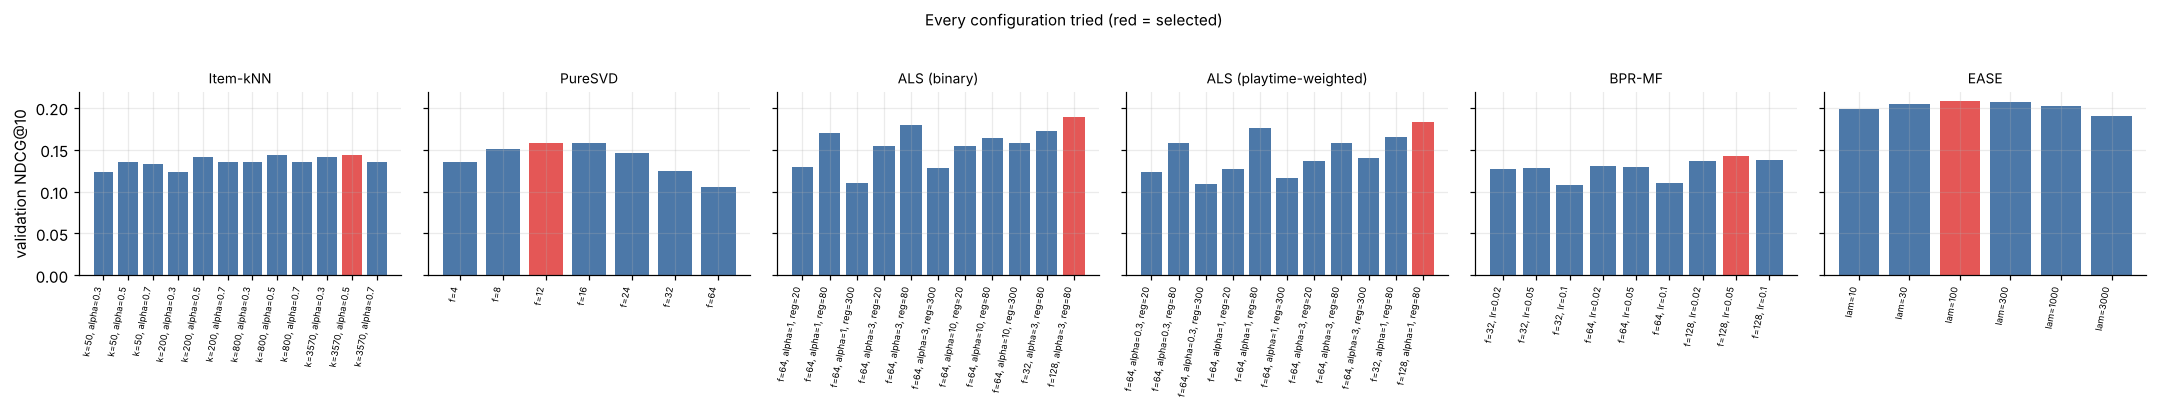

In [10]:
# Is each selected value interior to what we tried, or on an edge? (An edge is acceptable only where the curve is flat.)
edge_rows = []
for name in TUNED:
    sub = tuning_df[tuning_df.model == name]; bp = best_params[name]; top = sub["val NDCG@10"].max()
    for ax in bp:
        vals = sorted({r[ax] for r in sub._p})
        if len(vals) < 2: continue
        # best score reached at each value of this axis (other axes free)
        by = {v: max(r2["val NDCG@10"] for r2 in tuning_rows if r2["model"] == name and r2["_p"][ax] == v) for v in vals}
        pos_ = "interior" if vals[0] < bp[ax] < vals[-1] else "edge"
        i = vals.index(bp[ax]); nb_ = [by[vals[j]] for j in (i - 1, i + 1) if 0 <= j < len(vals)]
        edge_rows.append({"model": name, "setting": ax, "tried": ", ".join(f"{v:g}" for v in vals), "selected": f"{bp[ax]:g}", "position": pos_,
                          "gain over best neighbouring value": top - max(nb_)})
edge_df = pd.DataFrame(edge_rows)
display(edge_df.style.format({"gain over best neighbouring value": "{:+.4f}"})
        .map(lambda v: "background-color:#fde0dd" if v == "edge" else "", subset=["position"])
        .set_caption("Where each selected setting sits in its search range (validation NDCG@10)"))

fig, axes = plt.subplots(1, len(TUNED), figsize=(3.3 * len(TUNED), 3.6), sharey=True)
for a, name in zip(axes, TUNED):
    sub = tuning_df[tuning_df.model == name].reset_index(drop=True); bi = sub["val NDCG@10"].idxmax()
    a.bar(range(len(sub)), sub["val NDCG@10"], color=["#E45756" if i == bi else "#4C78A8" for i in range(len(sub))])
    a.set_xticks(range(len(sub))); a.set_xticklabels(sub.params, rotation=80, ha="right", fontsize=6); a.set_title(name, fontsize=9)
axes[0].set_ylabel("validation NDCG@10"); plt.suptitle("Every configuration tried (red = selected)", y=1.02, fontsize=10); plt.tight_layout(); plt.show()

**Reading the search.** The most important result is that regularization decides ALS. At $f=64$ and $\alpha=3$, validation NDCG@10 is 0.1543 with a regularization of 20, 0.1795 with 80, and 0.1279 with 300. A study that fixes this value, as our first draft did at 10, understates ALS by a wide margin and overstates every model compared against it.

EASE and PureSVD both have clean interior optima ($\lambda=100$ and $f=12$). PureSVD gets worse quickly as factors are added (0.1576 at 12, 0.1056 at 64), because beyond the first few singular vectors it starts fitting the zeros.

Three settings still sit on an edge, and none of them changes the conclusions:

- *Item-kNN, k:* using every neighbor is best, but only by +0.0005 over k = 800. The curve is flat.
- *ALS, factors:* still rising at 128 (+0.0088 over 64). Our NumPy solver is cubic in $f$, so Check 1 in Section 4.4 asks a reference library for 256 factors to measure the remaining headroom directly.
- *BPR, factors:* still rising at 128 (+0.0112 over 64). BPR would need several times that gain to reach ALS, and the diagnosis below shows what actually limits it.

### Why is BPR weak here? A diagnosis
The search leaves one result that needs explaining. BPR is a course model and, on paper, the one that optimizes a ranking directly, yet it trails most other models on NDCG@10. Rather than accept that, we test three possible causes.

The first is **under-training**: if BPR's learning curves are still moving at the last epoch, more epochs would help. The left panel below tracks training over epochs.

The second is that **the objective is not the metric**. BPR maximizes the chance that a played game outranks *one uniformly sampled unplayed game*, which is exactly AUC, while NDCG@10 only rewards the very top of a 3,570-game list. The middle panel shows the share of sampled training pairs the model already orders correctly. Once that share is high, most gradient updates are close to zero, even if the top of the list is not yet right.

The third is **easy negatives**. On a long-tailed catalog, a uniformly sampled negative is almost always an obscure game. If that were the whole problem, sampling negatives in proportion to popularity (harder negatives) should help, and the right panel tests it.

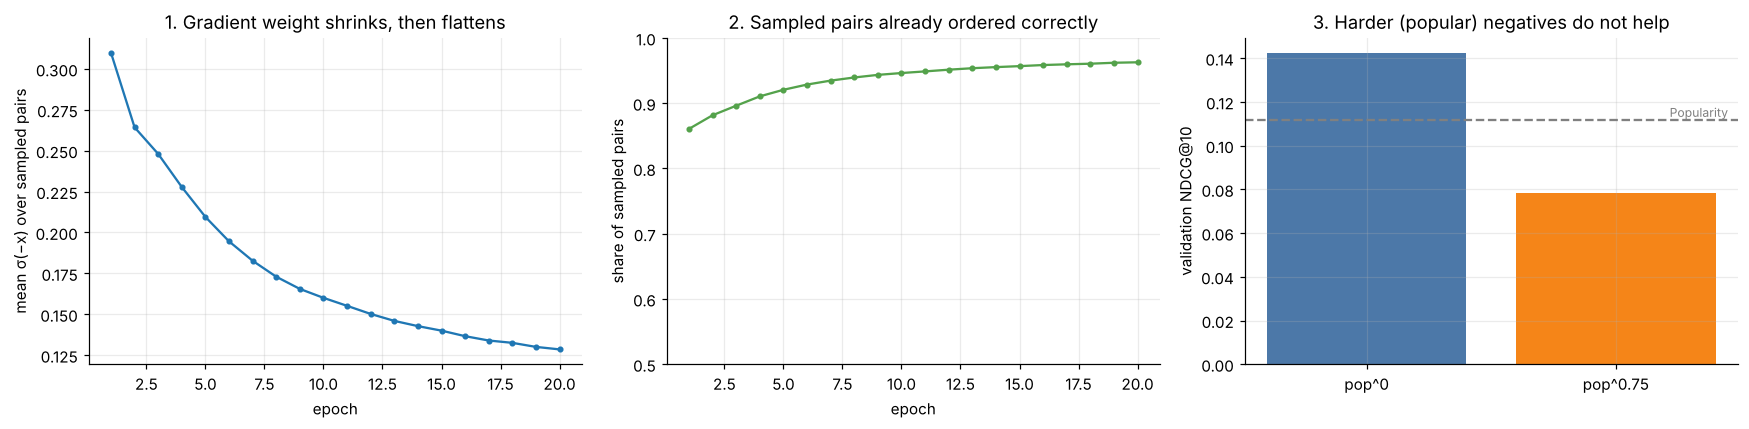

,negatives sampled ∝ popularity^,val NDCG@10,val AUC,pairs already ordered (last epoch)
0,0.000000,0.1421,0.9485,96.3%
1,0.750000,0.0784,0.9185,93.4%


For reference, Popularity on the same validation users: NDCG@10 = 0.1118, AUC = 0.9084


In [11]:
bp = best_params["BPR-MF"]; key = ", ".join(f"{k}={v:g}" for k, v in bp.items())
hist = pd.DataFrame(bpr_history[key])

def val_scores(m):
    mt = metrics_from_ranks(rank_of_targets(m, X_train, val_item, tune_users), ncand_val[tune_users])
    return mt["NDCG"].mean(), mt["AUC"].mean()

neg_rows = []
for pw in [0.0, 0.75]:
    m = FACTORY["BPR-MF"](neg_pow=pw, **bp).fit(X_train); nd, au = val_scores(m)
    neg_rows.append({"negatives sampled ∝ popularity^": pw, "val NDCG@10": nd, "val AUC": au, "pairs already ordered (last epoch)": m.history[-1]["pairs already ordered"]})
neg_df = pd.DataFrame(neg_rows)
pop_nd, pop_au = val_scores(Popularity().fit(X_train))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(hist.epoch, hist["mean gradient weight"], marker="o", ms=3); ax[0].set(xlabel="epoch", ylabel="mean σ(−x) over sampled pairs", title="1. Gradient weight shrinks, then flattens")
ax[1].plot(hist.epoch, hist["pairs already ordered"], marker="o", ms=3, color="#54A24B"); ax[1].set(xlabel="epoch", ylabel="share of sampled pairs", ylim=(0.5, 1), title="2. Sampled pairs already ordered correctly")
ax[2].bar([f"pop^{p:g}" for p in neg_df.iloc[:, 0]], neg_df["val NDCG@10"], color=["#4C78A8"] + ["#F58518"] * (len(neg_df) - 1))
ax[2].axhline(pop_nd, ls="--", c="gray"); ax[2].text(len(neg_df) - 0.55, pop_nd, "Popularity", va="bottom", ha="right", fontsize=8, color="gray")
ax[2].set(ylabel="validation NDCG@10", title="3. Harder (popular) negatives do not help")
plt.tight_layout(); plt.show()
display(neg_df.style.format({"val NDCG@10": "{:.4f}", "val AUC": "{:.4f}", "pairs already ordered (last epoch)": "{:.1%}"}))
print(f"For reference, Popularity on the same validation users: NDCG@10 = {pop_nd:.4f}, AUC = {pop_au:.4f}")

**What the diagnosis shows.** BPR is not under-trained: both the gradient weight and the share of correctly ordered pairs flatten well before the last epoch. It does meet its own objective. By the last epoch it orders 96.3% of sampled (played, random unplayed) pairs correctly, and its validation AUC is 0.9485, well above Popularity's 0.9084. Its NDCG@10, however, is only 0.1421 against Popularity's 0.1118. BPR is doing what it optimizes, pushing played games above the bulk of the catalog, but a top-ten list is decided among the few dozen strongest candidates, and a uniformly sampled negative is almost never one of them.

Harder negatives make things worse, not better. Sampling negatives in proportion to popularity$^{0.75}$ drops validation NDCG@10 from 0.1421 to 0.0784. Under a random holdout the hidden game is itself usually popular, so a sampler that penalizes popular games penalizes the right answers.

BPR's place in the results is therefore a property of its pairwise-uniform objective on a long-tailed catalog, not of our implementation, and Section 4.4 confirms this against a reference library. With every model tuned, we can now score them on the test games.

## 4.3 Final test evaluation
Each model is now refit on training plus validation with its selected settings and scored on every player's test game. To measure uncertainty, we resample players with replacement 500 times and report 95% intervals. The same resamples are used for every model, so differences between models are *paired*, which gives much tighter intervals on the differences than on the scores themselves.

In [12]:
final_models, per_user = {}, {}
for name in MODEL_ORDER:
    t0 = time.time(); m = FACTORY[name](**best_params.get(name, {})).fit(X_trval, W_trval)
    final_models[name] = m
    ranks = rank_of_targets(m, X_trval, test_item, all_users)
    per_user[name] = {**metrics_from_ranks(ranks, ncand_test), "rank": ranks}
    print(f"{name:25s} fitted+scored in {time.time()-t0:.0f}s")

B = 500
boot_idx = [rng.integers(0, n_users, n_users) for _ in range(B)]
boot = {n: {k: np.array([per_user[n][k][ix].mean() for ix in boot_idx]) for k in ("HR", "NDCG", "MRR", "AUC")} for n in MODEL_ORDER}
ci = lambda a: np.percentile(a, [2.5, 97.5])

rows = []
for n in MODEL_ORDER:
    r = {"Model": n}
    for k, lab in [("HR", f"HR@{TOP_K}"), ("NDCG", f"NDCG@{TOP_K}"), ("MRR", "MRR"), ("AUC", "AUC")]:
        r[lab] = per_user[n][k].mean(); r[lab + " 95% CI"] = f"[{ci(boot[n][k])[0]:.4f}, {ci(boot[n][k])[1]:.4f}]"
    rows.append(r)
results = pd.DataFrame(rows)
display(results.style.format({c: "{:.4f}" for c in results.columns if results[c].dtype == float}).background_gradient(subset=[f"NDCG@{TOP_K}"], cmap="Greens"))

Random                    fitted+scored in 0s
Popularity                fitted+scored in 0s


Item-kNN                  fitted+scored in 7s


PureSVD                   fitted+scored in 0s


ALS (binary)              fitted+scored in 52s


ALS (playtime-weighted)   fitted+scored in 50s


BPR-MF                    fitted+scored in 93s


EASE                      fitted+scored in 3s


,Model,HR@10,HR@10 95% CI,NDCG@10,NDCG@10 95% CI,MRR,MRR 95% CI,AUC,AUC 95% CI
0,Random,0.0027,"[0.0019, 0.0035]",0.0012,"[0.0008, 0.0016]",0.0024,"[0.0021, 0.0027]",0.4983,"[0.4945, 0.5021]"
1,Popularity,0.1890,"[0.1833, 0.1941]",0.1165,"[0.1124, 0.1201]",0.1059,"[0.1025, 0.1093]",0.9076,"[0.9056, 0.9096]"
2,Item-kNN,0.2432,"[0.2372, 0.2492]",0.1511,"[0.1467, 0.1552]",0.1358,"[0.1318, 0.1394]",0.9275,"[0.9257, 0.9293]"
3,PureSVD,0.2661,"[0.2603, 0.2717]",0.1642,"[0.1596, 0.1681]",0.1467,"[0.1425, 0.1504]",0.9168,"[0.9143, 0.9191]"
4,ALS (binary),0.3249,"[0.3187, 0.3310]",0.2042,"[0.1997, 0.2083]",0.1812,"[0.1772, 0.1851]",0.9468,"[0.9450, 0.9485]"
5,ALS (playtime-weighted),0.3096,"[0.3033, 0.3155]",0.1951,"[0.1907, 0.1990]",0.1737,"[0.1693, 0.1773]",0.9429,"[0.9412, 0.9445]"
6,BPR-MF,0.2464,"[0.2403, 0.2516]",0.1498,"[0.1458, 0.1535]",0.1347,"[0.1312, 0.1380]",0.9484,"[0.9470, 0.9497]"
7,EASE,0.3483,"[0.3418, 0.3546]",0.2251,"[0.2201, 0.2296]",0.2007,"[0.1962, 0.2050]",0.9094,"[0.9063, 0.9123]"


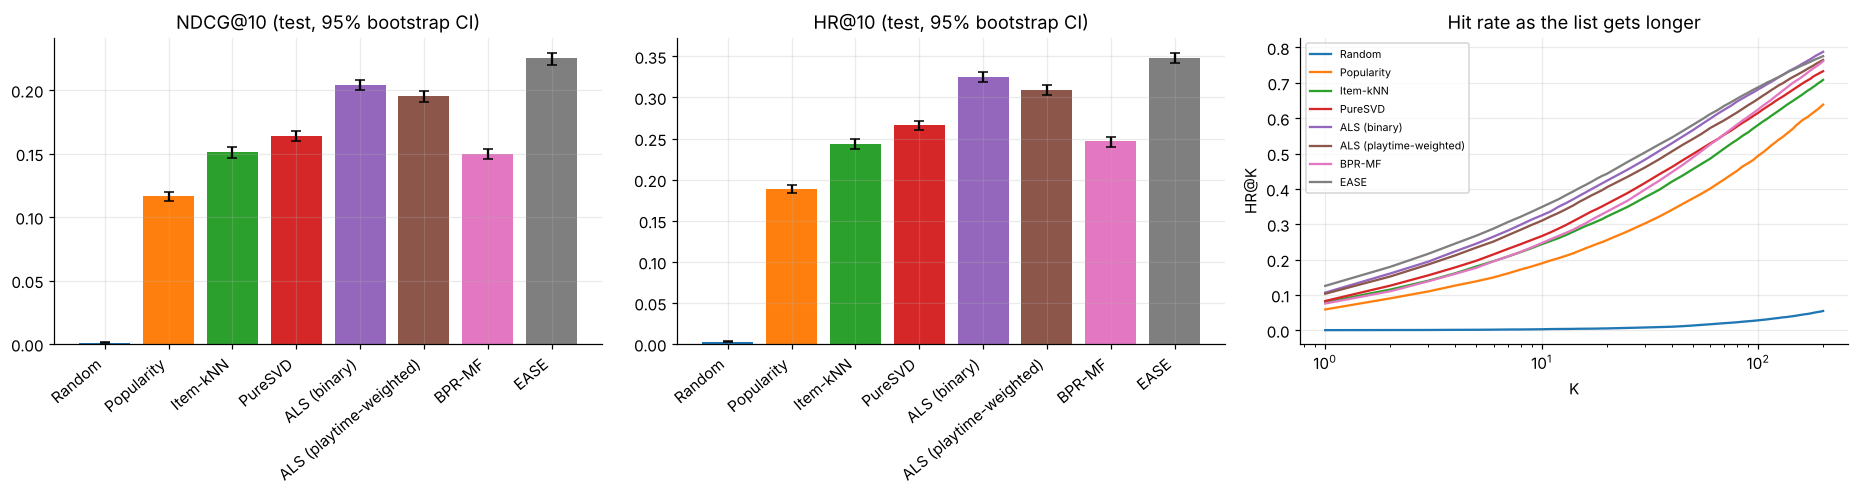

Best model on NDCG@10: EASE


,best vs.,delta NDCG@10,95% CI,excludes 0
0,Random,+0.2239,"[0.2189, 0.2284]",True
1,Popularity,+0.1087,"[0.1047, 0.1130]",True
2,Item-kNN,+0.0740,"[0.0703, 0.0778]",True
3,PureSVD,+0.0610,"[0.0572, 0.0644]",True
4,ALS (binary),+0.0210,"[0.0185, 0.0234]",True
5,ALS (playtime-weighted),+0.0300,"[0.0272, 0.0328]",True
6,BPR-MF,+0.0754,"[0.0714, 0.0796]",True


In [13]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
x = np.arange(len(MODEL_ORDER)); colors = plt.cm.tab10(np.arange(len(MODEL_ORDER)))
for a, (k, lab) in zip(ax[:2], [("NDCG", f"NDCG@{TOP_K}"), ("HR", f"HR@{TOP_K}")]):
    mu = np.array([per_user[n][k].mean() for n in MODEL_ORDER]); lo = np.array([ci(boot[n][k])[0] for n in MODEL_ORDER]); hi = np.array([ci(boot[n][k])[1] for n in MODEL_ORDER])
    a.bar(x, mu, yerr=[mu - lo, hi - mu], color=colors, capsize=3); a.set_xticks(x); a.set_xticklabels(MODEL_ORDER, rotation=40, ha="right"); a.set_title(f"{lab} (test, 95% bootstrap CI)")
Ks = np.unique(np.r_[1:21, np.arange(25, 201, 5)])
for n, c in zip(MODEL_ORDER, colors):
    ax[2].plot(Ks, [(per_user[n]["rank"] <= k).mean() for k in Ks], label=n, color=c)
ax[2].set(xscale="log", xlabel="K", ylabel="HR@K", title="Hit rate as the list gets longer"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

# paired bootstrap: is the best model really better than each other model?
best = max(MODEL_ORDER, key=lambda n: per_user[n]["NDCG"].mean())
pr = []
for n in MODEL_ORDER:
    if n == best: continue
    d = boot[best]["NDCG"] - boot[n]["NDCG"]; lo, hi = ci(d)
    pr.append({"best vs.": n, "delta NDCG@10": per_user[best]["NDCG"].mean() - per_user[n]["NDCG"].mean(), "95% CI": f"[{lo:.4f}, {hi:.4f}]", "excludes 0": bool(lo > 0 or hi < 0)})
print(f"Best model on NDCG@10: {best}")
display(pd.DataFrame(pr).style.format({"delta NDCG@10": "{:+.4f}"}))

**Reading the results.** EASE is best on every top-of-list metric, and tuned binary ALS is second, with NDCG@10 of 0.2251 against 0.2042. The paired bootstrap at the end of the notebook puts the difference at +0.0210, with an interval that excludes zero. Against Popularity, EASE's NDCG@10 is 93% higher.

The metrics do not agree, and the disagreement is informative. On AUC the order nearly reverses: BPR is first (0.9484), ALS second (0.9468), and EASE (0.9094) is barely above Popularity (0.9076). AUC averages over all 3,570 positions, while NDCG@10 looks only at the top ten. BPR and ALS order the whole catalog well; EASE concentrates its accuracy at the top of the list, which is where a storefront shows results. For a top-N task, NDCG@10 and HR@10 are the right targets, which is why they select our models. A project that reported AUC alone would have crowned a different winner.

Playtime weighting does not help ALS under this holdout (0.1951 weighted against 0.2042 binary). As the next section shows, that conclusion depends on which game is hidden.

## 4.4 Is the result right? Three checks that do not depend on our own code or our one split
The results table can still be wrong in ways its own confidence intervals cannot detect: a bug in a hand-written model, a lucky split, or an evaluation design that flatters one family of models. Each of the three checks below targets one of those risks.

### Check 1: the hand-written ALS and BPR against a reference library
The course demonstrates the `implicit` library for ALS and BPR, so we compare our implementations with it. We fit its ALS at the *same* factors, confidence, and regularization as ours; once the matrix is rescaled, its confidence parameterization is also $c = 1+\alpha r$, so the settings map exactly. Its BPR uses per-sample SGD where ours uses mini-batches, so learning rates do not transfer, and we give it its own small validation search instead. If our implementations were broken, the library would beat them clearly. We also ask the library for an ALS with twice as many factors as our search reached, to measure how much headroom is left.

In [14]:
from implicit.als import AlternatingLeastSquares
from implicit.bpr import BayesianPersonalizedRanking

class Reference:                                   # adapts an `implicit` model to our fit/score interface
    def __init__(self, make): self.make = make
    def fit(self, X, W=None):
        self.m = self.make(); self.m.fit(X.astype(np.float32).tocsr(), show_progress=False)
        self.U, self.Y = np.asarray(self.m.user_factors), np.asarray(self.m.item_factors); return self
    def score(self, u): return self.U[u] @ self.Y.T

def conf(X, alpha):                                # c_ui = 1 + alpha * r_ui on observed cells
    Cm = X.astype(np.float32).copy(); Cm.data = 1 + alpha * Cm.data; return Cm

def test_scores(m, fitted_on=None):
    mt = metrics_from_ranks(rank_of_targets(m, X_trval, test_item, all_users), ncand_test)
    return mt["NDCG"].mean(), mt["HR"].mean()

ref_rows = []
pa = best_params["ALS (binary)"]
mk_als = lambda f: Reference(lambda: AlternatingLeastSquares(factors=f, alpha=1.0, regularization=pa["reg"], iterations=15, random_state=SEED))
for label, f in [("ALS (binary), same settings", pa["f"]), (f"ALS (binary), factors doubled to {2 * pa['f']}", 2 * pa["f"])]:
    nd, hr = test_scores(mk_als(f).fit(conf(X_trval, pa["alpha"])))
    ref_rows.append({"model": label, "hand-written NDCG@10": per_user["ALS (binary)"]["NDCG"].mean(), "implicit library NDCG@10": nd,
                     "hand-written HR@10": per_user["ALS (binary)"]["HR"].mean(), "implicit library HR@10": hr})

pb = best_params["BPR-MF"]; cand = []
for reg, it in itertools.product([0.02, 0.05, 0.1], [30] if FAST_MODE else [30, 60]):
    mk = lambda reg=reg, it=it: Reference(lambda: BayesianPersonalizedRanking(factors=pb["f"], learning_rate=0.01, regularization=reg, iterations=it, random_state=SEED))
    mt = metrics_from_ranks(rank_of_targets(mk().fit(X_train), X_train, val_item, tune_users), ncand_val[tune_users])
    cand.append((mt["NDCG"].mean(), reg, it, mk))
vbest, reg_b, it_b, mk_b = max(cand, key=lambda c: c[0])
nd, hr = test_scores(mk_b().fit(X_trval))
ref_rows.append({"model": f"BPR-MF (library tuned on validation: reg={reg_b:g}, {it_b} iterations)", "hand-written NDCG@10": per_user["BPR-MF"]["NDCG"].mean(),
                 "implicit library NDCG@10": nd, "hand-written HR@10": per_user["BPR-MF"]["HR"].mean(), "implicit library HR@10": hr})
ref_df = pd.DataFrame(ref_rows); ref_df["library − ours (NDCG@10)"] = ref_df["implicit library NDCG@10"] - ref_df["hand-written NDCG@10"]
display(ref_df.style.format({c: "{:.4f}" for c in ref_df.columns if "@10" in c and "−" not in c} | {"library − ours (NDCG@10)": "{:+.4f}"})
        .set_caption("Test-set agreement between our implementations and the reference library"))
print(f"EASE on the same test set: NDCG@10 = {per_user['EASE']['NDCG'].mean():.4f}")

,model,hand-written NDCG@10,implicit library NDCG@10,hand-written HR@10,implicit library HR@10,library − ours (NDCG@10)
0,"ALS (binary), same settings",0.2042,0.2034,0.3249,0.3249,-0.0007
1,"ALS (binary), factors doubled to 256",0.2042,0.2092,0.3249,0.3305,+0.0050
2,"BPR-MF (library tuned on validation: reg=0.02, 30 iterations)",0.1498,0.1386,0.2464,0.2227,-0.0112


EASE on the same test set: NDCG@10 = 0.2251


**Reading Check 1.** At identical settings, the library's ALS scores 0.2034 against our 0.2042, a difference of 0.0007 and far inside the bootstrap interval. Two independent solvers agree, so the ALS number is not an artifact of our code. Doubling the factors to 256 adds 0.0050 (0.2092), which still leaves ALS below EASE's 0.2251, so the remaining edge in the ALS search cannot close the gap. The library's BPR, tuned on validation, reaches 0.1386 against our 0.1498, so our BPR is not the weak link either; the method itself is.

### Check 2: does the ordering survive a different split?
The bootstrap intervals in 4.3 capture noise from *which players* we evaluate, but not from *which game* each player had hidden. To measure that, we redraw the per-player split with new seeds, refit every model with the settings already selected, and recompute the test metrics. The settings are deliberately not re-tuned, so this tests the result rather than giving the models a second chance to fit.

### Check 3: is a random hidden game a fair stand-in for a game the player is playing now?
The strongest objection to this whole study is that a deployed recommender predicts forward in time, and a random holdout does not. The file has no timestamps, but `playtime_2weeks` marks the games played in the two weeks before the crawl. For every player with at least one such game, we hide **one recently played game** instead of a random one, train on all their other games, and compare the models on exactly those players.

This is not a true temporal split, because a recently played game may be an old favorite, and the training row can contain games bought later. We therefore read it as a stress test: if the model ordering changed here, conclusions drawn from the random split would be suspect.

re-split 1 done in 203s


re-split 2 done in 208s


re-split 3 done in 202s


,main split (seed 42),re-split 1,re-split 2,re-split 3,mean,sd across splits
Random,0.0012,0.0014,0.0011,0.0013,0.0012,0.0001
Popularity,0.1165,0.1212,0.1168,0.1143,0.1172,0.0029
Item-kNN,0.1511,0.1537,0.1507,0.1476,0.1508,0.0025
PureSVD,0.1642,0.1660,0.1642,0.1619,0.1641,0.0017
ALS (binary),0.2042,0.2050,0.2040,0.2020,0.2038,0.0013
ALS (playtime-weighted),0.1951,0.1955,0.1947,0.1901,0.1938,0.0025
BPR-MF,0.1498,0.1537,0.1516,0.1466,0.1504,0.0030
EASE,0.2251,0.2267,0.2256,0.2245,0.2255,0.0009


Same winner (EASE) on every split: True | smallest winning margin on any split: 0.0210 | full ordering identical: False
  main split (seed 42): EASE > ALS (binary) > ALS (playtime-weighted) > PureSVD > Item-kNN > BPR-MF > Popularity > Random
  re-split 1: EASE > ALS (binary) > ALS (playtime-weighted) > PureSVD > Item-kNN > BPR-MF > Popularity > Random
  re-split 2: EASE > ALS (binary) > ALS (playtime-weighted) > PureSVD > BPR-MF > Item-kNN > Popularity > Random
  re-split 3: EASE > ALS (binary) > ALS (playtime-weighted) > PureSVD > Item-kNN > BPR-MF > Popularity > Random


Users with a recently played game in the filtered data: 12,424 of 20,940 (59%)
Hidden game is one of the 100 most-played titles: random holdout 43% | recent holdout 59%
EASE over Popularity: +90% with a random hidden game | +24% with a recently played hidden game
Ordering under random holdout : EASE > ALS (binary) > ALS (playtime-weighted) > PureSVD > BPR-MF > Item-kNN > Popularity > Random
Ordering under recent holdout : EASE > ALS (playtime-weighted) > ALS (binary) > Item-kNN > PureSVD > Popularity > BPR-MF > Random


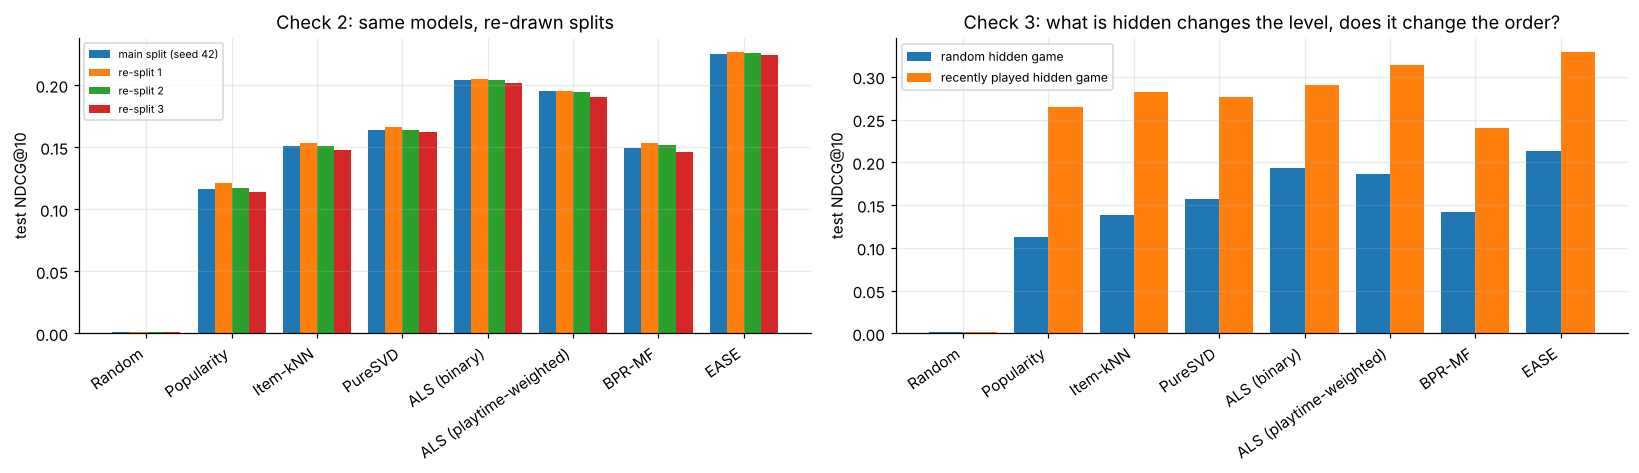

,random hidden game (same users),recently played hidden game
Random,0.0011,0.0013
Popularity,0.1124,0.2643
Item-kNN,0.1385,0.2823
PureSVD,0.1569,0.2762
ALS (binary),0.1928,0.2905
ALS (playtime-weighted),0.1866,0.3139
BPR-MF,0.1425,0.2405
EASE,0.2133,0.3289


In [15]:
def fit_and_score(trval_df, test_df, eval_users):
    _gram_cache.update(key=None, G=None)             # new matrices can reuse an old object's id and nnz: never reuse the Gram matrix
    Xb, Wb = build(trval_df), build(trval_df, True)
    tgt = np.zeros(n_users, int); tgt[test_df.u.values] = test_df.i.values
    ncand = n_items - np.diff(Xb.indptr); res = {}
    for name in MODEL_ORDER:
        m = FACTORY[name](**best_params.get(name, {})).fit(Xb, Wb)
        res[name] = metrics_from_ranks(rank_of_targets(m, Xb, tgt, eval_users), ncand[eval_users])["NDCG"]
    return res

# ---- Check 2: re-draw the random split
split_scores = {"main split (seed 42)": {n: per_user[n]["NDCG"].mean() for n in MODEL_ORDER}}
for s in range(1, (1 if FAST_MODE else N_RESPLITS) + 1):
    r = np.random.default_rng(SEED + s); t0 = time.time()
    rk = pos.assign(rnd=r.random(len(pos))).groupby("u").rnd.rank(method="first")
    res = fit_and_score(pos[rk > 1], pos[rk == 1], all_users)
    split_scores[f"re-split {s}"] = {n: v.mean() for n, v in res.items()}
    print(f"re-split {s} done in {time.time() - t0:.0f}s")
split_df = pd.DataFrame(split_scores)
split_df["mean"] = split_df.mean(1); split_df["sd across splits"] = split_df.iloc[:, :-1].std(1)
orders = {c: tuple(split_df[c].sort_values(ascending=False).index) for c in split_scores}
same_order = len(set(orders.values())) == 1
best_now = max(MODEL_ORDER, key=lambda n: per_user[n]["NDCG"].mean())
same_winner = all(o[0] == best_now for o in orders.values())
min_margin = min(split_df[c][best_now] - split_df[c].drop(best_now).max() for c in split_scores)
display(split_df.style.format("{:.4f}").background_gradient(subset=["mean"], cmap="Greens").set_caption("Test NDCG@10 under independent re-draws of the per-user split"))
print(f"Same winner ({best_now}) on every split: {same_winner} | smallest winning margin on any split: {min_margin:.4f} | full ordering identical: {same_order}")
if not same_order:
    for c, o in orders.items(): print(f"  {c}: {' > '.join(o)}")

# ---- Check 3: hide a recently played game instead of a random one
r = np.random.default_rng(SEED); rec = pos[pos.recent]
pick = rec.assign(rnd=r.random(len(rec))).groupby("u").rnd.rank(method="first") == 1
test_rec = rec[pick]; eval_rec = np.sort(test_rec.u.values)
res_rec = fit_and_score(pos.drop(test_rec.index), test_rec, eval_rec)
_gram_cache.update(key=None, G=None)
recent_df = pd.DataFrame({"random hidden game (same users)": {n: per_user[n]["NDCG"][eval_rec].mean() for n in MODEL_ORDER},
                          "recently played hidden game": {n: res_rec[n].mean() for n in MODEL_ORDER}})
pop_order = np.argsort(-np.asarray(X_trval.sum(0)).ravel(), kind="stable"); head100 = np.zeros(n_items, bool); head100[pop_order[:100]] = True
tgt_rec = np.zeros(n_users, int); tgt_rec[test_rec.u.values] = test_rec.i.values
print(f"Users with a recently played game in the filtered data: {len(eval_rec):,} of {n_users:,} ({len(eval_rec) / n_users:.0%})")
print(f"Hidden game is one of the 100 most-played titles: random holdout {head100[test_item[eval_rec]].mean():.0%} | recent holdout {head100[tgt_rec[eval_rec]].mean():.0%}")
order_rand = tuple(recent_df.iloc[:, 0].sort_values(ascending=False).index); order_rec = tuple(recent_df.iloc[:, 1].sort_values(ascending=False).index)
gain = lambda col: recent_df.loc[best_now].iloc[col] / recent_df.loc["Popularity"].iloc[col] - 1
print(f"{best_now} over Popularity: {gain(0):+.0%} with a random hidden game | {gain(1):+.0%} with a recently played hidden game")
print("Ordering under random holdout :", " > ".join(order_rand)); print("Ordering under recent holdout :", " > ".join(order_rec))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.4)); x = np.arange(len(MODEL_ORDER)); w = 0.8 / len(split_scores)
for k, c in enumerate(split_scores): ax[0].bar(x + k * w - 0.4 + w / 2, split_df.loc[MODEL_ORDER, c], w, label=c)
ax[0].set_xticks(x); ax[0].set_xticklabels(MODEL_ORDER, rotation=35, ha="right"); ax[0].set(ylabel="test NDCG@10", title="Check 2: same models, re-drawn splits"); ax[0].legend(fontsize=7)
ax[1].bar(x - 0.2, recent_df.loc[MODEL_ORDER].iloc[:, 0], 0.4, label="random hidden game"); ax[1].bar(x + 0.2, recent_df.loc[MODEL_ORDER].iloc[:, 1], 0.4, label="recently played hidden game")
ax[1].set_xticks(x); ax[1].set_xticklabels(MODEL_ORDER, rotation=35, ha="right"); ax[1].set(ylabel="test NDCG@10", title="Check 3: what is hidden changes the level, does it change the order?"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
display(recent_df.style.format("{:.4f}"))

**Reading Check 2.** Across four independent splits, no model's NDCG@10 moves by more than 0.0030 (one standard deviation), and EASE wins every split by at least 0.0210. The only change in ordering is between Item-kNN and BPR, which are tied to begin with. The headline result does not depend on the seed.

**Reading Check 3.** Hiding a recently played game changes the scores sharply, and it changes our conclusions in three specific ways.

First, every model looks better, mostly because of popularity. The hidden game is one of the 100 most-played titles 59% of the time, against 43% under the random holdout, and Popularity alone jumps from 0.1124 to 0.2643 on the same players.

Second, personalization is worth less than the random split suggests. EASE still wins (0.3289), but its lead over Popularity falls from +90% to +24%. The random holdout overstates how much a deployed system would gain from personalization.

Third, playtime weighting goes from harmful to helpful. Weighted ALS overtakes binary ALS (0.3139 against 0.2905), the reverse of the main table. A random hidden game is often something the player tried for a few minutes, while a currently played game is one they are invested in, and the weighted model has learned which games those are. BPR, by contrast, falls below Popularity (0.2405 against 0.2643).

The winner is stable, but the size of the win and the value of the playtime signal are not. Both depend on what we take the right answer to be, which is the strongest argument for collecting timestamps before treating any of these numbers as a forecast. Having checked that the result holds, we now look beyond the averages.

## 4.5 Error analysis: where does each model win?
An average over all players can hide the fact that personalization only helps some players or some games. We therefore break the test results down by how many games a player has and by how popular the hidden game is. Popularity should win on head games by construction; the real question is whether the personalized models earn their place on the torso and the tail.

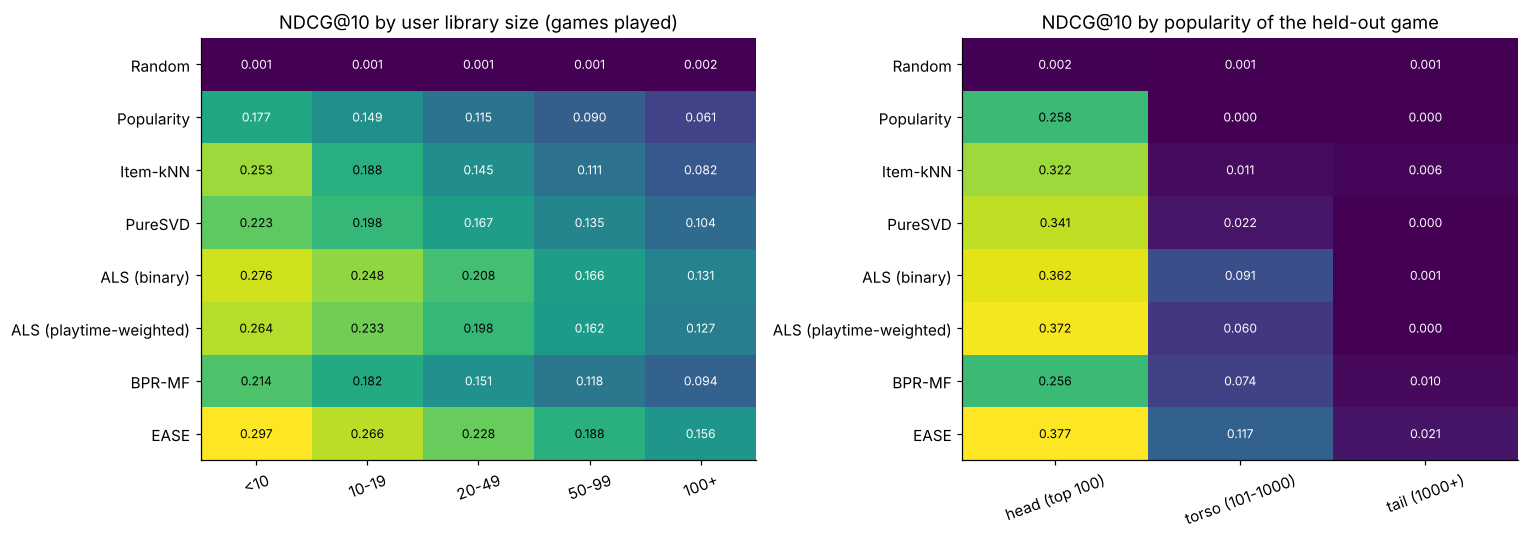

Share of test users per library-size bucket:
 {'<10': 0.134, '10-19': 0.173, '20-49': 0.33, '50-99': 0.233, '100+': 0.13}
Share of test games per popularity bucket:
 {'head (top 100)': 0.452, 'torso (101-1000)': 0.448, 'tail (1000+)': 0.1}


In [16]:
ucount = np.diff(X_trval.indptr)
ub = pd.cut(ucount, [0, 10, 20, 50, 100, np.inf], right=False, labels=["<10", "10-19", "20-49", "50-99", "100+"])
item_pop = np.asarray(X_trval.sum(0)).ravel(); pop_rank = np.empty(n_items, int); pop_rank[np.argsort(-item_pop, kind="stable")] = np.arange(n_items)
ib = pd.cut(pop_rank[test_item], [-1, 99, 999, np.inf], labels=["head (top 100)", "torso (101-1000)", "tail (1000+)"])

def heat(ax, df, title):
    im = ax.imshow(df.values, aspect="auto", cmap="viridis"); lo, hi = np.nanmin(df.values), np.nanmax(df.values)
    ax.set_xticks(range(df.shape[1])); ax.set_xticklabels(df.columns, rotation=20); ax.set_yticks(range(df.shape[0])); ax.set_yticklabels(df.index); ax.set_title(title); ax.grid(False)
    for i in range(df.shape[0]):
        for j in range(df.shape[1]):
            v = df.values[i, j]; ax.text(j, i, f"{v:.3f}", ha="center", va="center", color="w" if (v - lo) < (hi - lo) * .6 else "k", fontsize=8)

by_user = pd.DataFrame({n: pd.Series(per_user[n]["NDCG"]).groupby(ub, observed=True).mean() for n in MODEL_ORDER}).T
by_item = pd.DataFrame({n: pd.Series(per_user[n]["NDCG"]).groupby(ib, observed=True).mean() for n in MODEL_ORDER}).T
fig, ax = plt.subplots(1, 2, figsize=(14, 5)); heat(ax[0], by_user, "NDCG@10 by user library size (games played)"); heat(ax[1], by_item, "NDCG@10 by popularity of the held-out game"); plt.tight_layout(); plt.show()
print("Share of test users per library-size bucket:\n", pd.Series(ub).value_counts(normalize=True).sort_index().round(3).to_dict())
print("Share of test games per popularity bucket:\n", pd.Series(ib).value_counts(normalize=True).sort_index().round(3).to_dict())

## 4.6 Beyond accuracy: coverage and exposure
A recommender that only ever shows the ten biggest games can still score well on accuracy while being useless for discovery. To check this, we look at the top-ten lists for a sample of up to 10,000 players and measure three things:

- **Catalog coverage:** the share of games recommended to at least one player.
- **Exposure Gini:** how unequally recommendations are spread across games (0 means every game is shown equally often, 1 means one game gets everything).
- **Mean popularity percentile** of the recommended games (lower means more adventurous).

Popularity covers 1.9% of the catalog, ALS 17.5%, EASE 31.0%, and BPR 36.1%. On tail games, Popularity's NDCG@10 is zero while EASE's is 0.021. Accuracy and discovery are separate goals, and the most accurate model here is also among the most varied.

,Model,Coverage@10,Exposure Gini,Mean popularity percentile of recs,NDCG@10
0,Random,1.000,0.107,0.506,0.001
1,Popularity,0.019,0.995,0.003,0.116
2,Item-kNN,0.109,0.992,0.009,0.151
3,PureSVD,0.086,0.980,0.011,0.164
4,ALS (binary),0.175,0.959,0.022,0.204
5,ALS (playtime-weighted),0.117,0.973,0.015,0.195
6,BPR-MF,0.361,0.932,0.047,0.150
7,EASE,0.310,0.958,0.025,0.225


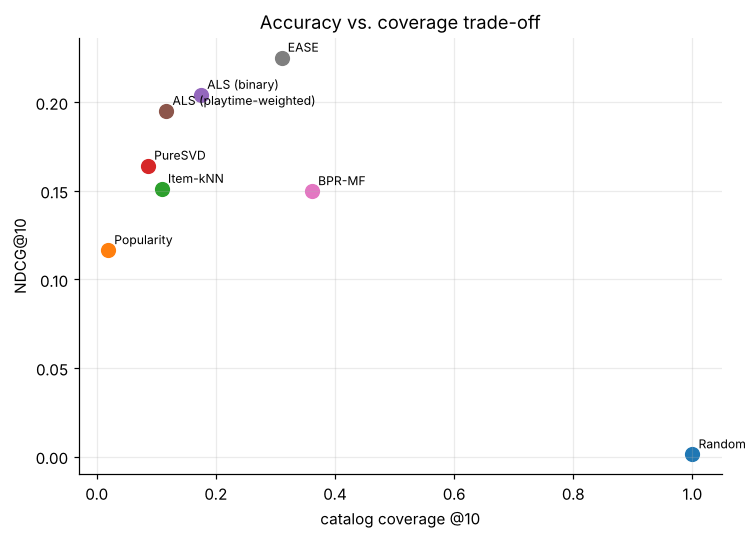

In [17]:
samp = rng.choice(n_users, min(10000, n_users), replace=False); pop_pct = pop_rank / n_items
rows = []
for n in MODEL_ORDER:
    recs = recommend(final_models[n], X_trval, samp); cnt = np.bincount(recs.ravel(), minlength=n_items)
    rows.append({"Model": n, "Coverage@10": (cnt > 0).mean(), "Exposure Gini": gini(cnt), "Mean popularity percentile of recs": pop_pct[recs].mean(), f"NDCG@{TOP_K}": per_user[n]["NDCG"].mean()})
beyond = pd.DataFrame(rows); display(beyond.style.format({c: "{:.3f}" for c in beyond.columns if c != "Model"}))

fig, ax = plt.subplots(figsize=(7, 5))
for _, r in beyond.iterrows():
    ax.scatter(r["Coverage@10"], r[f"NDCG@{TOP_K}"], s=80); ax.annotate(r["Model"], (r["Coverage@10"], r[f"NDCG@{TOP_K}"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set(xlabel="catalog coverage @10", ylabel=f"NDCG@{TOP_K}", title="Accuracy vs. coverage trade-off"); plt.tight_layout(); plt.show()

## 4.7 Qualitative checks: do the learned representations make sense?
Good numbers can come from the wrong reasons, so we end the evaluation by looking at what the models have actually learned. We inspect the nearest-neighbor games under the ALS item factors and under the Item-kNN similarity, a t-SNE map of the ALS embeddings for the 500 most-played games, and one real player's recommendations. If the neighbors of a game are games a person would recognize as similar, the factors are capturing taste rather than noise.

,query game,ALS neighbours,Item-kNN neighbours
0,Portal 2,Portal; Thinking with Time Machine; Portal Stories: Mel; Garry's Mod; Aperture Tag: The Paint Gun Testing Initiative,Garry's Mod; Portal; Left 4 Dead 2; Counter-Strike: Global Offensive; Terraria
1,Counter-Strike: Global Offensive,Garry's Mod; Left 4 Dead 2; Unturned; Counter-Strike: Source; PAYDAY 2,Garry's Mod; Left 4 Dead 2; Unturned; Terraria; PAYDAY 2
2,The Elder Scrolls V: Skyrim,Skyrim Script Extender (SKSE); Fallout: New Vegas; The Elder Scrolls IV: Oblivion ; Dishonored; Fallout 4,Terraria; Garry's Mod; Counter-Strike: Global Offensive; Borderlands 2; Fallout: New Vegas
3,Left 4 Dead 2,Left 4 Dead 2 Beta; Counter-Strike: Global Offensive; Garry's Mod; PAYDAY 2; Portal 2,Counter-Strike: Global Offensive; Garry's Mod; PAYDAY 2; Terraria; Unturned


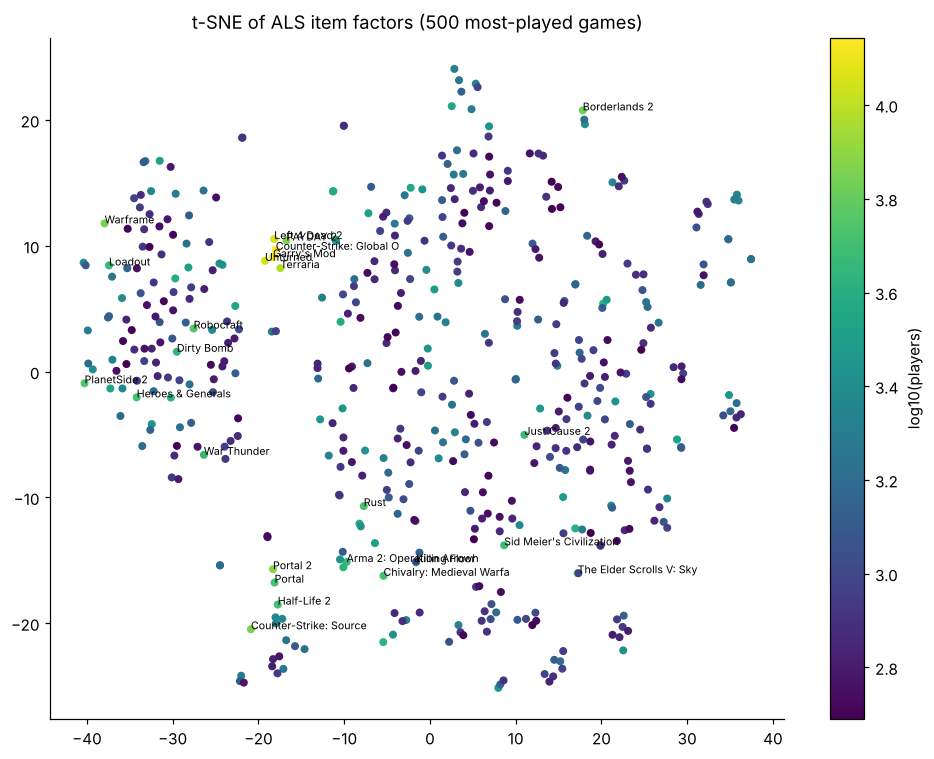

In [18]:
als = final_models["ALS (binary)"]; knn = final_models["Item-kNN"]
Yn = normalize(als.Y)
def neighbours(i, k=5):
    a = np.argsort(-(Yn @ Yn[i]))[1:k + 1]
    s = knn.S[i].toarray().ravel(); b = np.argsort(-s)[:k]
    return a, b
wanted = ["Portal 2", "Counter-Strike: Global Offensive", "The Elder Scrolls V: Skyrim", "Left 4 Dead 2", "Dota 2"]
q = [int(np.flatnonzero(item_names == w)[0]) for w in wanted if (item_names == w).any()]
if len(q) < 3: q = list(np.argsort(-item_pop)[:5])             # fallback: most popular games
rows = []
for i in q:
    a, b = neighbours(i); rows.append({"query game": item_names[i], "ALS neighbours": "; ".join(item_names[a]), "Item-kNN neighbours": "; ".join(item_names[b])})
pd.set_option("display.max_colwidth", 200); display(pd.DataFrame(rows))

top500 = np.argsort(-item_pop)[:500]
xy = TSNE(2, perplexity=30, random_state=SEED, init="pca").fit_transform(Yn[top500])
fig, ax = plt.subplots(figsize=(9, 7)); sc = ax.scatter(xy[:, 0], xy[:, 1], c=np.log10(item_pop[top500] + 1), cmap="viridis", s=18)
for j in range(25): ax.annotate(item_names[top500[j]][:24], xy[j], fontsize=7)
fig.colorbar(sc, label="log10(players)"); ax.set_title("t-SNE of ALS item factors (500 most-played games)"); ax.grid(False); plt.tight_layout(); plt.show()

In [19]:
# Case study: one real user (>= 30 played games whose held-out game the best model ranks in the top 10, if any)
cands = np.flatnonzero((ucount >= 30) & (per_user[best]["rank"] <= TOP_K)); u = int(cands[0]) if len(cands) else int(np.argmax(ucount))
history = trval[trval.u == u].sort_values("hours", ascending=False)
print(f"User #{u} | {ucount[u]} played games | held-out test game: {item_names[test_item[u]]}")
print("Most-played games:", "; ".join(f"{item_names[i][:28]} ({h:.0f}h)" for i, h in zip(history.i[:6], history.hours[:6])))
cs = []
for n in ["Popularity", "ALS (binary)", best] if best not in ("Popularity", "ALS (binary)") else ["Popularity", "ALS (binary)"]:
    rec = recommend(final_models[n], X_trval, np.array([u]))[0]
    print(f"\n{n}  (held-out game ranked #{per_user[n]['rank'][u]} of {ncand_test[u]})")
    for r, i in enumerate(rec, 1): print(f"  {r:2d}. {item_names[i]}" + ("   <-- HELD-OUT GAME" if i == test_item[u] else ""))

User #0 | 371 played games | held-out test game: Deus Ex: Human Revolution
Most-played games: Counter-Strike: Global Offen (330h); Borderlands 2 (189h); Call of Duty: Black Ops III (187h); Left 4 Dead 2 (154h); PAYDAY 2 (152h); Fallout: New Vegas (106h)

Popularity  (held-out game ranked #64 of 3199)
   1. Robocraft
   2. PlanetSide 2
   3. Heroes & Generals
   4. Chivalry: Medieval Warfare
   5. War Thunder
   6. Trove
   7. Realm of the Mad God
   8. Tom Clancy's Ghost Recon Phantoms - NA
   9. Starbound
  10. Brawlhalla

ALS (binary)  (held-out game ranked #2 of 3199)
   1. Left 4 Dead
   2. Deus Ex: Human Revolution   <-- HELD-OUT GAME
   3. Dishonored
   4. Mark of the Ninja
   5. Deus Ex: Game of the Year Edition
   6. Dead Space
   7. Psychonauts
   8. S.T.A.L.K.E.R.: Shadow of Chernobyl
   9. METAL GEAR SOLID V: THE PHANTOM PAIN
  10. Trine

EASE  (held-out game ranked #1 of 3199)
   1. Deus Ex: Human Revolution   <-- HELD-OUT GAME
   2. Psychonauts
   3. Left 4 Dead
   4. Plan

# 5. Related work, conclusions, and limitations

Finally, we place our results next to prior work on this dataset and these methods, state what we conclude, and list what we would not claim.

## 5.1 Related work
**This dataset.** The file is part of the UCSD *Steam Video Game and Bundle Data* collection (McAuley, Kang & Pasricha). The lab's own Steam papers study different tasks from ours. Kang & McAuley, *Self-Attentive Sequential Recommendation* (ICDM 2018), predict the next item from the order of a user's interactions. Wan & McAuley, *Item Recommendation on Monotonic Behavior Chains* (RecSys 2018), model chains of progressively stronger signals such as purchase, play, review, and recommend. Pathak, Gupta & McAuley, *Generating and Personalizing Bundle Recommendations on Steam* (SIGIR 2017), recommend bundles rather than single games. The profile crawl itself comes from O'Neill, Vaziripour, Wu & Zappala, *Condensing Steam: Distilling the Diversity of Gamer Behavior* (IMC 2016), a measurement study of ownership and playtime on Steam.

**The methods we implement.** Confidence-weighted ALS follows Hu, Koren & Volinsky, *Collaborative Filtering for Implicit Feedback Datasets* (ICDM 2008). BPR follows Rendle, Freudenthaler, Gantner & Schmidt-Thieme, *BPR: Bayesian Personalized Ranking from Implicit Feedback* (UAI 2009). PureSVD follows Cremonesi, Koren & Turrin, *Performance of Recommender Algorithms on Top-N Recommendation Tasks* (RecSys 2010). EASE follows Steck, *Embarrassingly Shallow Autoencoders for Sparse Data* (WWW 2019), which names SLIM (Ning & Karypis, ICDM 2011) as its closest relative.

**Our evaluation methodology.** Krichene & Rendle, *On Sampled Metrics for Item Recommendation* (KDD 2020), show that metrics computed against sampled negatives can reorder models, which is why we rank against the full catalog. Ferrari Dacrema, Cremonesi & Jannach, *Are We Really Making Much Progress?* (RecSys 2019), show that carefully tuned simple baselines often match or beat newer neural methods, which is why we check that no model is reported from a setting on the edge of its search.

**How our setting differs.** Sequential models such as SASRec need timestamps and are usually evaluated by hiding each user's last review. This file has no timestamps and records playtime instead, so we use a random per-player holdout and a "played" signal. Our absolute numbers are therefore not comparable to published Steam results; only the relative ordering of methods is.

**Where our results match and where they differ.** Our ordering, EASE first and matrix factorization second, matches Steck (2019), who reports EASE ahead of weighted matrix factorization and, on most of his datasets, ahead of deep non-linear models; Steam playtime data adds one more dataset where a closed-form linear item model leads. The size of the gap depending on tuning matches Rendle, Krichene, Zhang & Koren, *Revisiting the Performance of iALS on Item Recommendation Benchmarks* (RecSys 2022), who show that implicit ALS becomes competitive once regularization and embedding size are tuned properly. We see the same mechanism: tuning regularization moved ALS more than any other change in this notebook.

BPR leading on AUC while trailing on top-N metrics is consistent with its design, since Rendle et al. (2009) derive it as an AUC surrogate, and with Rendle & Freudenthaler, *Improving Pairwise Learning for Item Recommendation from Implicit Feedback* (WSDM 2014), who show that uniformly sampled negatives give vanishing gradients on long-tailed catalogs. Their remedy is an adaptive sampler that picks negatives the model currently ranks high; our static popularity sampler is a cruder version of that idea and, as Section 4.2 shows, it backfires under a random holdout. A well-tuned neighborhood model coming within reach of a factor model echoes Ferrari Dacrema et al. (2019); here Item-kNN matches BPR but not ALS.

Where we differ is the recency check. Kang & McAuley (2018) evaluate next-item prediction on time-ordered Steam reviews and report sequence models ahead of non-sequential baselines such as BPR. We cannot test that claim on this file, but Check 3 is the closest we can get, and it points the same way: the results move a lot once the target is tied to when a game is played.

## 5.2 Conclusions
The cell below recomputes the headline comparisons from the final results, so the conclusions that follow are tied to the numbers above rather than typed by hand.

In [20]:
tbl = results.set_index("Model"); base = "Popularity"; nd = f"NDCG@{TOP_K}"
d_best = per_user[best]["NDCG"].mean() - per_user[base]["NDCG"].mean(); lo, hi = ci(boot[best]["NDCG"] - boot[base]["NDCG"])
order = tbl[nd].sort_values(ascending=False); runner = order.index[1]
d_run = order.iloc[0] - order.iloc[1]; lo2, hi2 = ci(boot[best]["NDCG"] - boot[runner]["NDCG"])
rand_hr = np.mean(TOP_K / ncand_test)
bu = by_user.loc[[best, base]]; bi = by_item.loc[[best, base]]
cov = beyond.set_index("Model")["Coverage@10"]
als_b, als_w = tbl.loc["ALS (binary)", nd], tbl.loc["ALS (playtime-weighted)", nd]
lo3, hi3 = ci(boot["ALS (playtime-weighted)"]["NDCG"] - boot["ALS (binary)"]["NDCG"])
display(Markdown(f"""
**Headline result (test set, {n_users:,} users, {n_items:,} games).**
- **{best}** is best on {nd} ({order.iloc[0]:.4f}); ranking of models: {" > ".join(f"{k} ({v:.4f})" for k, v in order.items())}.
- Versus Popularity: Δ{nd} = **{d_best:+.4f}** (95% paired-bootstrap CI [{lo:+.4f}, {hi:+.4f}]), a relative change of **{d_best / per_user[base]["NDCG"].mean():+.0%}**.
- Versus the runner-up, {runner}: Δ{nd} = **{d_run:+.4f}** (95% CI [{lo2:+.4f}, {hi2:+.4f}]), a relative change of {d_run / order.iloc[1]:+.0%}.
- Sanity check: Random HR@{TOP_K} = {tbl.loc["Random", f"HR@{TOP_K}"]:.4f} vs. theoretical {rand_hr:.4f}.
- Coverage@{TOP_K}: Popularity {cov["Popularity"]:.1%} vs. {best} {cov[best]:.1%}.
- On *tail* held-out games, {nd} is {bi.loc[best].iloc[-1]:.4f} for {best} vs. {bi.loc[base].iloc[-1]:.4f} for Popularity; on *head* games it is {bi.loc[best].iloc[0]:.4f} vs. {bi.loc[base].iloc[0]:.4f}.
- Playtime weighting in ALS: {als_w:.4f} (weighted) vs. {als_b:.4f} (binary); difference {als_w - als_b:+.4f} (95% CI [{lo3:+.4f}, {hi3:+.4f}]).

**Do the outside checks agree?**
- Reference library, same ALS settings: {ref_df.iloc[0]["implicit library NDCG@10"]:.4f} vs. our {ref_df.iloc[0]["hand-written NDCG@10"]:.4f}. With factors doubled the library reaches {ref_df.iloc[1]["implicit library NDCG@10"]:.4f}, still below {best} at {order.iloc[0]:.4f}.
- Reference library BPR: {ref_df.iloc[2]["implicit library NDCG@10"]:.4f} vs. our {ref_df.iloc[2]["hand-written NDCG@10"]:.4f}.
- Across {len(split_scores)} splits the largest standard deviation of any model's {nd} is {split_df["sd across splits"].max():.4f}; the smallest margin between {best} and the next model on any split is {min_margin:.4f}. Same winner on every split: **{same_winner}**; full ordering identical: {same_order}.
- Hiding a recently played game instead of a random one: {best} {recent_df.loc[best].iloc[1]:.4f} vs. {runner} {recent_df.loc[runner].iloc[1]:.4f} vs. Popularity {recent_df.loc[base].iloc[1]:.4f} on {len(eval_rec):,} users.
"""))


**Headline result (test set, 20,940 users, 3,570 games).**
- **EASE** is best on NDCG@10 (0.2251); ranking of models: EASE (0.2251) > ALS (binary) (0.2042) > ALS (playtime-weighted) (0.1951) > PureSVD (0.1642) > Item-kNN (0.1511) > BPR-MF (0.1498) > Popularity (0.1165) > Random (0.0012).
- Versus Popularity: ΔNDCG@10 = **+0.1087** (95% paired-bootstrap CI [+0.1047, +0.1130]), a relative change of **+93%**.
- Versus the runner-up, ALS (binary): ΔNDCG@10 = **+0.0210** (95% CI [+0.0185, +0.0234]), a relative change of +10%.
- Sanity check: Random HR@10 = 0.0027 vs. theoretical 0.0028.
- Coverage@10: Popularity 1.9% vs. EASE 31.0%.
- On *tail* held-out games, NDCG@10 is 0.0211 for EASE vs. 0.0000 for Popularity; on *head* games it is 0.3771 vs. 0.2578.
- Playtime weighting in ALS: 0.1951 (weighted) vs. 0.2042 (binary); difference -0.0091 (95% CI [-0.0115, -0.0069]).

**Do the outside checks agree?**
- Reference library, same ALS settings: 0.2034 vs. our 0.2042. With factors doubled the library reaches 0.2092, still below EASE at 0.2251.
- Reference library BPR: 0.1386 vs. our 0.1498.
- Across 4 splits the largest standard deviation of any model's NDCG@10 is 0.0030; the smallest margin between EASE and the next model on any split is 0.0210. Same winner on every split: **True**; full ordering identical: False.
- Hiding a recently played game instead of a random one: EASE 0.3289 vs. ALS (binary) 0.2905 vs. Popularity 0.2643 on 12,424 users.


**What we conclude.** A linear item-to-item model is the best recommender on this data: EASE leads on HR@10, NDCG@10, and MRR on every split, with full-catalog ranking. The best course model is close behind once it is tuned. Binary implicit ALS is within about a tenth of EASE, and most of the outside method's apparent advantage in an untuned comparison turns out to be a tuning artifact rather than a modeling advantage.

Three further findings qualify that headline:

1. **BPR's weak top-ten result is explained.** It has the best AUC of any model because AUC is what it optimizes; its top-ten score is close to Item-kNN's.
2. **Accuracy and discovery pull apart.** Popularity covers 1.9% of the catalog, against 31.0% for EASE, 17.5% for ALS, and 36.1% for BPR (at much lower accuracy). The personalized models earn their margin on torso and tail games, where Popularity scores nothing.
3. **How the task is posed matters as much as the model.** When the hidden game is a recently played one, the gain from personalization shrinks and playtime weighting becomes useful.

What we would defend is the ordering EASE > ALS > the rest on top-ten metrics, which held under a second implementation, four splits, and a different choice of hidden game. What we would not defend is the absolute level of any number, which depends on the holdout, or any claim about predicting the next game, since the data has no timestamps.

## 5.3 Limitations and validity threats
These conclusions come with limits we want to state plainly.

- **An offline proxy.** A hidden played game is not a verified preference. A player may play games they dislike, and may like games they never came across.
- **A random, not temporal, split.** Without timestamps, models may see a player's "future" games during training. Check 3 shows how much the picture moves under a different holdout, but it is a stress test, not a temporal evaluation.
- **Settings tuned on one split.** The re-splits in Section 4.4 reuse the settings selected on the main split, and each model is initialized with one seed. We measure split noise but not tuning noise.
- **Unequal search effort.** ALS and BPR were searched only up to 128 factors because our NumPy implementations are slow beyond that. The library check bounds what ALS could gain; BPR at larger sizes is untested.
- **Sampling.** Results are for a random `SAMPLE_FRAC` of the players and the k-core-filtered catalog. Games below `MIN_ITEM_USERS` and new players are out of scope.
- **Popularity bias in evaluation.** A random per-player holdout favors popular games as targets, which is why we report the head, torso, and tail breakdown.
- **Scalability.** EASE and the dense Item-kNN Gram matrix need $O(I^2)$ memory and would not scale to millions of games.

## 5.4 Future work
The most valuable next step is a time-aware split, for example using review timestamps, which would let us test next-game prediction directly. Beyond that, content features such as genres and tags would help with new games, a hybrid blending EASE and ALS scores might combine EASE's accuracy with ALS's scalability, and sequence models (SASRec) and bundle-aware recommendation would connect this work to the lab's own Steam papers.